In [81]:
%pip install matplotlib seaborn pandas


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [82]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [83]:
BASE_DIR = Path().resolve().parent.parent / "output_files"
aiup_csv_path = BASE_DIR / "ai_usage_profile.csv"
sqp_csv_path = BASE_DIR / "software_quality_profile.csv"

aiup_df = pd.read_csv(aiup_csv_path)
sqp_df = pd.read_csv(sqp_csv_path)

In [84]:
combined_aiup_sqp = pd.merge(
    aiup_df[["repository_id", "snapshot_commit", "prob_ai_whodunit", "code_churn", "prob_machine_droiddetect"]],
    sqp_df[["repository_id", "snapshot_commit", "lines", "languages", "date"]],
    on=["repository_id", "snapshot_commit"],
    how="outer",
    suffixes=("_aiup", "_sqp")
)

display(combined_aiup_sqp.head())

,repository_id,snapshot_commit,prob_ai_whodunit,code_churn,prob_machine_droiddetect,lines,languages,date
0,2017_KDPRO-SINTEF_BowtieTool,00811ab24654bf01eeac78da88c1923f7d3c42e6,0.0044,1.0000,0.0703,374398.0000,"[{'val': 'web', 'count': 142567}, {'val': 'js'...",2017-10-16T23:07:32+02:00
1,2017_KDPRO-SINTEF_BowtieTool,00e5d198f97070bd10ce19bacd0aaa1fe0a2bf5d,0.0588,33.0000,0.0882,377675.0000,"[{'val': 'web', 'count': 142577}, {'val': 'js'...",2017-11-09T14:54:00+01:00
2,2017_KDPRO-SINTEF_BowtieTool,05bd5392bbc6166cafc9c62a9d7e42dafe566629,NaN,NaN,NaN,357237.0000,"[{'val': 'web', 'count': 142370}, {'val': 'js'...",2017-11-12T14:34:37+01:00
3,2017_KDPRO-SINTEF_BowtieTool,069e9cfb9e359bf41fb05dd56381bf1bc268fb1d,NaN,NaN,NaN,357247.0000,"[{'val': 'web', 'count': 142370}, {'val': 'js'...",2017-11-13T14:59:20+01:00
4,2017_KDPRO-SINTEF_BowtieTool,0868ad0a92f4e44df1d366cdd8f56a3daa70506a,0.0033,45.0000,0.0963,379990.0000,"[{'val': 'web', 'count': 142577}, {'val': 'js'...",2017-10-29T13:02:26+01:00


In [85]:
def get_primary_language(langs):
    langs_lst = eval(langs) if isinstance(langs, str) else []
    
    if(not langs_lst):
        return None  # Return None if there are no languages
    
    # Return the val with the highest count
    return max(langs_lst, key=lambda x: x['count'])['val']


In [86]:
combined_aiup_sqp['primary_language'] = combined_aiup_sqp['languages'].apply(get_primary_language)

df = combined_aiup_sqp

In [87]:
from scipy import stats
import pandas as pd


def is_normal(p):
    return p is not None and p > 0.05

def extract_language_stats(df, ai_prob_col, contribution_col, high_threshold=0.75):
    df = df.copy()

    languages = df['primary_language'].dropna().unique()
    results = []

    for lang in sorted(languages):

        lang_df = df[df['primary_language'] == lang].dropna(subset=[ai_prob_col, contribution_col])
        lang_df[ai_prob_col] = pd.to_numeric(lang_df[ai_prob_col], errors="coerce")
        lang_df["ai_group"] = lang_df[ai_prob_col].apply(
            lambda x: "High" if pd.notna(x) and float(x) >= high_threshold else "Low"
        )

        if len(lang_df) < 10:
            continue

        high_ai = lang_df[lang_df["ai_group"] == "High"][contribution_col]
        low_ai  = lang_df[lang_df["ai_group"] == "Low"][contribution_col]

        # Shapiro-Wilk normality test per group
        _, shapiro_p_high_ai = stats.shapiro(high_ai) if len(high_ai) >= 3 else (None, None)
        _, shapiro_p_low_ai  = stats.shapiro(low_ai)  if len(low_ai)  >= 3 else (None, None)
        is_normally_distributed = is_normal(shapiro_p_high_ai) and is_normal(shapiro_p_low_ai)

        # Mann-Whitney U: codesize ~ ai_group
        n1 = high_ai
        n2 = low_ai
        
        mw_u_high_ai,   mw_p   = stats.mannwhitneyu(n1, n2, alternative='two-sided')
        mw_u_low_ai    = len(n1) * len(n2) - mw_u_high_ai
        min_u = min(mw_u_high_ai, mw_u_low_ai)
        r_mw = 1 - (2 * min_u) / (len(n1) * len(n2))        
        
        # Pearson r: codesize ~ ai_prob (continuous)
        pearson_r_contribution_ai,  pearson_p_contribution_ai  = stats.pearsonr(lang_df[ai_prob_col], lang_df[contribution_col])

        # Spearman r: codesize ~ ai_prob (continuous)
        spearman_r_contribution_ai, spearman_p_contribution_ai = stats.spearmanr(lang_df[ai_prob_col], lang_df[contribution_col])

        results.append({
            "Language":                             lang,
            "N":                                    len(lang_df),
            "Median contribution (High AI)":        round(high_ai.median(), 3),
            "Median contribution (Low AI)":         round(low_ai.median(), 3),
            "Mean contribution (High AI)":          round(high_ai.mean(), 3),
            "Mean contribution (Low AI)":           round(low_ai.mean(), 3),
            "Mean contribution (High AI, norm.)":   round(high_ai.mean() / lang_df[contribution_col].mean(), 3),
            "Mean contribution (Low AI, norm.)":    round(low_ai.mean() / lang_df[contribution_col].mean(), 3),
            "U(contribution|ai_group)":             round(mw_u_high_ai, 1),
            "U(contribution|~ai_group)":            round(mw_u_low_ai, 1),
            "p_mw(contribution|ai_group)":          round(mw_p, 4),
            "r_mw(contribution|ai_group)":          round(r_mw, 3),
            "r_pearson(contribution~ai_prob)":      round(pearson_r_contribution_ai, 3),
            "p_pearson(contribution~ai_prob)":      round(pearson_p_contribution_ai, 4),
            "r_spearman(contribution~ai_prob)":     round(spearman_r_contribution_ai, 3),
            "p_spearman(contribution~ai_prob)":     round(spearman_p_contribution_ai, 4),
            "Normal?":                              "Yes" if is_normally_distributed else "No",
            "p_sw_high_ai":                        round(shapiro_p_high_ai, 8) if shapiro_p_high_ai is not None else "N/A",
            "p_sw_low_ai":                         round(shapiro_p_low_ai, 8) if shapiro_p_low_ai is not None else "N/A",
            "high_ai_n":                          len(high_ai),
            "low_ai_n":                           len(low_ai)
        })

    results_df = pd.DataFrame(results)
    
    # Print neatly
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 200)
    pd.set_option('display.float_format', '{:.4f}'.format)
    print(results_df.to_string(index=False))
    
    return results_df

In [88]:
# ── Universal colour palette ──────────────────────────────────────────────────
# All colours tested for mutual harmony and sufficient contrast on white/light bg

# Group / category colours
C_AI        = "#2563EB"   # blue        – AI-product group
C_DEV       = "#575B64"   # slate grey  – no AI-product group
C_ORANGE    = "#EA6C00"   # orange      – third category / accent
C_GREEN     = "#0F8C4A"   # green       – fourth category
C_RED       = "#CC1F1F"   # red         – fifth category
C_PURPLE    = "#6D28D9"   # violet      – sixth category
C_TEAL      = "#0891B2"   # teal        – seventh category

# A ready-made ordered list for cycling through groups
CATEGORY_COLORS = [C_AI, C_ORANGE, C_GREEN, C_RED, C_PURPLE, C_TEAL, C_DEV]

# Significance / annotation colours
C_SIG       = "#0F8C4A"   # green  – statistically significant  (matches C_GREEN)
C_TREND     = "#EA6C00"   # amber  – trending                   (matches C_ORANGE)
C_NS        = "#BFC8D7"   # light grey – not significant

# Direction colours (right-panel bars)
C_POS       = "#2563EB"   # blue – AI group higher              (matches C_AI)
C_NEG       = "#CC1F1F"   # red  – no-AI group higher           (matches C_RED)

# Text colours
C_TEXT      = "#111827"   # near-black – significant rows / primary labels
C_TEXT_NS   = "#6B7280"   # mid grey   – non-significant rows
C_TEXT_SOFT = "#9CA3AF"   # light grey – annotations / secondary labels

# Row / background shading
C_ROW_SIG   = "#F0FDF4"   # very light green – significant row highlight
C_ROW_TREND = "#FFF7ED"   # very light amber – trending row highlight
C_ROW_ALT   = "#F9FAFB"   # off-white        – alternating row stripe
C_ROW       = "#FFFFFF"   # white            – default row
C_ROW_SHADING = "#F9FAFB"  # light grey for alternating row shading

# Hatch patterns paired with CATEGORY_COLORS for B&W printing
CATEGORY_HATCHES = ["", "///", "...", "xxx", "\\\\\\", "|||", "+++"]

In [89]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np


def plot_results(results_df, ai_prob_col, size_col, high_threshold):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle("AI Usage vs Codebase Contributions by Language (" + ai_prob_col + " compared to " + size_col + ") with threshold " + str(high_threshold), fontsize=16, y=1.01)

    # ── 1. Pearson & Spearman r coefficients ──────────────────────────────────────
    ax1 = axes[0, 0]
    x = np.arange(len(results_df))
    width = 0.35
    ax1.bar(x - width/2, results_df["r_pearson(contribution~ai_prob)"],  width, label="r_pearson(contribution~ai_prob)",  color=C_TEAL, alpha=0.85)
    ax1.bar(x + width/2, results_df["r_spearman(contribution~ai_prob)"], width, label="r_spearman(contribution~ai_prob)", color=C_ORANGE, hatch=CATEGORY_HATCHES[1], alpha=0.85)

    ax1.axhline(0.5, color="green", linewidth=0.8, linestyle="--")
    ax1.axhline(-0.5, color="green", linewidth=0.8, linestyle="--", label="Strong (r=-0.5, -0.5)")
    ax1.axhline(0.3, color="orange", linewidth=0.8, linestyle="--")
    ax1.axhline(-0.3, color="orange", linewidth=0.8, linestyle="--", label="Moderate (r=0.3, -0.3)")
    ax1.axhline(0.1, color="red", linewidth=0.8, linestyle="--")
    ax1.axhline(-0.1, color="red", linewidth=0.8, linestyle="--", label="Weak (r=0.1, -0.1)")

    ax1.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax1.set_xticks(x)
    ax1.set_xticklabels(results_df["Language"], rotation=45, ha="right")
    ax1.set_ylabel("Correlation Coefficient")
    ax1.set_title("Pearson & Spearman Correlation by Language")
    ax1.legend()
    ax1.set_ylim(-0.6, 0.6)

    # ── 2. Mann-Whitney p-values (log scale) ──────────────────────────────────────
    ax2 = axes[0, 1]
    colors = [C_RED if p < 0.05 else C_NS for p in results_df["p_mw(contribution|ai_group)"]]
    bars = ax2.bar(results_df["Language"], results_df["p_mw(contribution|ai_group)"], color=colors, alpha=0.85)
    ax2.axhline(0.05, color=C_RED, linewidth=1.2, linestyle="--", label="p = 0.05")
    ax2.set_yscale("log")
    ax2.set_xticklabels(results_df["Language"], rotation=45, ha="right")
    ax2.set_ylabel("p-value (log scale)")
    ax2.set_title("Mann-Whitney p-values by Language")
    sig_patch   = mpatches.Patch(color=C_RED, alpha=0.85, label="Significant (p_mw < .05)")
    insig_patch = mpatches.Patch(color=C_NS, alpha=0.85, label="Non-significant (p_mw ≥ .05)")
    ax2.legend(handles=[sig_patch, insig_patch])

    # ── 3. Mean codebase size: High vs Low AI ───────────────────────────────────
    ax3 = axes[1, 0]
    x = np.arange(len(results_df))
    ax3.bar(x - width/2, results_df["Mean contribution (High AI, norm.)"], width, label="High AI (ai_prob > " + str(high_threshold) + ")", color=C_SIG, hatch=CATEGORY_HATCHES[1], alpha=0.85)
    ax3.bar(x + width/2, results_df["Mean contribution (Low AI, norm.)"],  width, label="Low AI (ai_prob < " + str(high_threshold) + ")",  color=C_AI, alpha=0.85)
    ax3.set_xticks(x)
    ax3.set_xticklabels(results_df["Language"], rotation=45, ha="right")
    ax3.set_ylabel("Mean Codebase Contribution (Normalised)")
    ax3.set_title("Mean Codebase Contribution (Normalised): High vs Low AI Group")
    ax3.legend()

    # ── 4. Sample sizes ───────────────────────────────────────────────────────────
    ax4 = axes[1, 1]
    bar_colors = [C_TEAL if n >= 100 else C_ORANGE for n in results_df["N"]]
    ax4.bar(results_df["Language"], results_df["N"], color=bar_colors, alpha=0.85)
    ax4.set_xticklabels(results_df["Language"], rotation=45, ha="right")
    ax4.set_ylabel("Number of Observations")
    ax4.set_title("Sample Size per Language")
    large_patch = mpatches.Patch(color=C_TEAL, alpha=0.85, label="n ≥ 100")
    small_patch = mpatches.Patch(color=C_ORANGE, alpha=0.85, label="n < 100")
    ax4.legend(handles=[large_patch, small_patch])

    plt.tight_layout()
    plt.show()

In [90]:
# "Language":                         lang,
#             "N":                                len(lang_df),
#             "Median codesize (High AI)":        round(high_ai.median(), 3),
#             "Median codesize (Low AI)":         round(low_ai.median(), 3),
#             "Mean codesize (High AI)":          round(high_ai.mean(), 3),
#             "Mean codesize (Low AI)":           round(low_ai.mean(), 3),
#             "Mean codesize (High AI, norm.)":   round(high_ai.mean() / lang_df[size_col].mean(), 3),
#             "Mean codesize (Low AI, norm.)":    round(low_ai.mean() / lang_df[size_col].mean(), 3),
#             "U(codesize|ai_group)":             round(mw_u_codesize_ai, 1),
#             "p_mw(codesize|ai_group)":          round(mw_p_codesize_ai, 4),
#             "t(codesize|ai_group)":             round(t_codesize_ai, 3),
#             "p_t(codesize|ai_group)":           round(t_p_codesize_ai, 4),
#             "r_pearson(codesize~ai_prob)":      round(pearson_r_codesize_ai, 3),
#             "p_pearson(codesize~ai_prob)":      round(pearson_p_codesize_ai, 4),
#             "r_spearman(codesize~ai_prob)":     round(spearman_r_codesize_ai, 3),
#             "p_spearman(codesize~ai_prob)":     round(spearman_p_codesize_ai, 4),
#             "Normal?":                          "Yes" if is_normally_distributed else "No",
#         })

def df_to_latex(results_df, ai_metric):
    cols_table1 = ["Language", "N", "Median contribution (High AI)", "Median contribution (Low AI)",
                   "Mean contribution (High AI, norm.)", "Mean contribution (Low AI, norm.)"]

    cols_table2 = ["Language", "U(contribution|ai_group)", "p_mw(contribution|ai_group)", "r_mw(contribution|ai_group)",
                   "r_pearson(contribution~ai_prob)", "p_pearson(contribution~ai_prob)", "r_spearman(contribution~ai_prob)", "p_spearman(contribution~ai_prob)", "Normal?"]

    print("% Table 1: Descriptive Statistics")
    print(results_df[cols_table1].to_latex(
        index=False,
        float_format="%.4f",
        caption="Statistical comparison of codebase size between high and low AI usage groups per language using " + ai_metric + " (1/2)",
        label="tab:stat_tests_" + ai_metric.replace("_", "\_").lower() + "_1"
    ))

    print("% Table 2: Statistical Tests")
    print(results_df[cols_table2].to_latex(
        index=False,
        float_format="%.4f",
        caption="Statistical comparison of codebase size between high and low AI usage groups per language using " + ai_metric + " (2/2)",
        label="tab:stat_tests_" + ai_metric.replace("_", "\_").lower() + "_2"
    ))

In [91]:
high_threshold = 0.6

size_col = "code_churn"
ai_prob_col = "prob_machine_droiddetect"


In [92]:
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

def plot_normality(df):
    languages = df['primary_language'].dropna().unique()
    
    for lang in languages:
        # Filter + copy to avoid SettingWithCopy issues
        lang_df = df[df['primary_language'] == lang].copy()

        # Convert to numeric
        lang_df[ai_prob_col] = pd.to_numeric(lang_df[ai_prob_col], errors="coerce")
        lang_df[size_col]    = pd.to_numeric(lang_df[size_col], errors="coerce")

        # Drop NaNs AFTER conversion
        lang_df = lang_df.dropna(subset=[ai_prob_col, size_col])

        if len(lang_df) < 10:
            continue

        # ── Shapiro-Wilk (overall, not grouped) ──
        _, p_size = stats.shapiro(lang_df[size_col]) if len(lang_df) >= 3 else (None, None)
        _, p_ai   = stats.shapiro(lang_df[ai_prob_col]) if len(lang_df) >= 3 else (None, None)

        # Safe formatting
        def fmt(x):
            try:
                return f"{float(x):.4f}"
            except:
                return "NA"

        # ── Plot setup ──
        fig, axes = plt.subplots(2, 2, figsize=(12, 6))

        fig.suptitle(
            f"{lang} | {size_col} p={fmt(p_size)}, {ai_prob_col} p={fmt(p_ai)}",
            fontsize=10, color=C_TEXT
        )

        # ── Histogram + KDE ──
        for ax, col, color in [
            (axes[0, 0], size_col, C_AI),
            (axes[0, 1], ai_prob_col, C_ORANGE),
        ]:
            data = lang_df[col]

            ax.hist(data, bins=30, color=color, alpha=0.5, density=True)

            # KDE
            try:
                from scipy.stats import gaussian_kde
                kde = gaussian_kde(data)
                xs = np.linspace(data.min(), data.max(), 200)
                ax.plot(xs, kde(xs), color=color, lw=1.8)
            except Exception:
                pass

            ax.set_title(f"{col} - histogram", fontsize=8, color=C_TEXT)
            ax.set_xlabel(col, fontsize=7, color=C_TEXT_NS)
            ax.set_ylabel("Density", fontsize=7, color=C_TEXT_NS)
            ax.tick_params(labelsize=7, colors=C_TEXT_NS)

            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)

            ax.set_facecolor(C_ROW)

        # ── Q-Q plots ──
        for ax, col, color in [
            (axes[1, 0], size_col, C_AI),
            (axes[1, 1], ai_prob_col, C_ORANGE),
        ]:
            data = lang_df[col]

            (osm, osr), (slope, intercept, _) = stats.probplot(data, dist="norm")

            ax.scatter(osm, osr, s=8, color=color, alpha=0.4)
            ax.plot(osm, slope * np.array(osm) + intercept,
                    color=C_TEXT_NS, lw=1.2, linestyle="--")

            ax.set_title(f"{col} - Q-Q plot", fontsize=8, color=C_TEXT)
            ax.set_xlabel("Theoretical quantiles", fontsize=7, color=C_TEXT_NS)
            ax.set_ylabel("Sample quantiles", fontsize=7, color=C_TEXT_NS)
            ax.tick_params(labelsize=7, colors=C_TEXT_NS)

            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)

            ax.set_facecolor(C_ROW)

        fig.tight_layout()
        plt.show()

In [106]:
LANGUAGE_TO_LABEL = {
    "css": "CSS",
    "docker": "Docker",
    "ipynb": "Jupyter Notebook",
    "java": "Java",
    "javascript": "JavaScript",
    "js": "JavaScript",
    "kotlin": "Kotlin",
    "python": "Python",
    "py": "Python",
    "rust": "Rust",
    "secrets": "Secrets",
    "typescript": "TypeScript",
    "ts": "TypeScript",
    "web": "Web",
    "xml": "XML",
}

In [150]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from matplotlib.lines import Line2D

plt.rcParams.update({
    "text.usetex":      False,
    "mathtext.fontset": "cm",
    "font.family":      "sans-serif",
    "font.size":        13,
    "hatch.linewidth":  1.5,
})

H_HIGH  = CATEGORY_HATCHES[1]
H_LOW   = CATEGORY_HATCHES[2]
H_SIG   = CATEGORY_HATCHES[1]
H_TREND = CATEGORY_HATCHES[2]
H_NS    = CATEGORY_HATCHES[3]

SYM_LAMBDA       = r"$\lambda$"
SYM_DELTA        = r"$\Delta$"
SYM_TAU          = r"$\tau$"
SYM_RHO          = r"$\rho$"
SYM_H            = r"$\mathcal{H}$"
SYM_L            = r"$\mathcal{L}$"
SYM_RHO_SP       = r"$\rho_{Spearman}$"
SYM_R_PEARSON    = r"$r_{Pearson}$"
SYM_R_MW         = r"$r_{MW}$"
SYM_P_MW         = r"$p_{MW}$"

FS_TITLE  = 18
FS_AXIS   = 16
FS_TICK   = 14
FS_LEGEND = 14
FS_ANNOT  = 16
FS_NOTE   = 14
FS_STAR   = 16


def _get_label(lang):
    """Map raw language string to display label."""
    return LANGUAGE_TO_LABEL.get(str(lang).lower(), str(lang))


def _style_ax(ax, title, ylabel, xlabel=r"$\lambda$  (primary language)"):
    ax.set_title(title, fontsize=FS_TITLE, color=C_TEXT, pad=10)
    ax.set_ylabel(ylabel, fontsize=FS_AXIS, color=C_TEXT)
    ax.set_xlabel(xlabel, fontsize=FS_AXIS, color=C_TEXT)
    ax.tick_params(axis="both", labelsize=FS_TICK, colors=C_TEXT)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#D1D5DB")
    ax.set_facecolor("white")
    ax.yaxis.set_tick_params(color="#D1D5DB")
    ax.xaxis.set_tick_params(color="#D1D5DB")


def _sig_stars(p):
    if p is None or p == "N/A":
        return "--"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def _patch(fc, ec, hatch, label, lw=0.9):
    return mpatches.Patch(facecolor=fc, edgecolor=ec, hatch=hatch,
                          linewidth=lw, label=label)


# =============================================================================
# Figure 1 - Normalised mean Δ: High vs Low AI group
# =============================================================================
def plot_h1_normalised_churn(results_df, high_threshold, save_path=None):
    langs     = results_df["Language"].tolist()
    labels    = [_get_label(l) for l in langs]
    x         = np.arange(len(langs))
    width     = 0.36

    norm_high = results_df["Mean contribution (High AI, norm.)"].tolist()
    norm_low  = results_df["Mean contribution (Low AI, norm.)"].tolist()
    p_mw      = results_df["p_mw(contribution|ai_group)"].tolist()

    fig, ax = plt.subplots(figsize=(14, 8), dpi=500)
    fig.patch.set_facecolor("white")

    bars_h = ax.bar(x - width / 2, norm_high, width,
                    facecolor=C_TEAL, edgecolor="white", hatch=H_HIGH,
                    linewidth=0.5, zorder=3,
                    label=r"High AI $(\tau \geq $" + f"{high_threshold}" + r"$)$")
    bars_l = ax.bar(x + width / 2, norm_low, width,
                    facecolor=C_PURPLE, edgecolor="white", hatch=H_LOW,
                    linewidth=0.5, zorder=3,
                    label=r"Low AI $(\tau < $" + f"{high_threshold}" + r"$)$")

    ax.axhline(1.0, color=C_TEXT, linewidth=1.1, linestyle="--",
               label=r"$\bar{\Delta}_{\lambda}$ (language mean)", zorder=2)

    ylim_top = max(max(norm_high, default=1), max(norm_low, default=1)) * 1.22
    ax.set_ylim(0, ylim_top)

    for bar, p in zip(bars_h, p_mw):
        lbl   = _sig_stars(p)
        color = C_SIG if lbl not in ("ns", "--") else C_TEXT_NS
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + ylim_top * 0.013,
                lbl, ha="center", va="bottom", fontsize=FS_STAR, color=color)

    for i, p in enumerate(p_mw):
        if isinstance(p, float) and p < 0.05:
            ax.axvspan(i - 0.5, i + 0.5, alpha=0.06, color=C_TEAL, zorder=1)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=FS_TICK)

    _style_ax(ax,
              title=(r"Normalised mean code churn $(\bar{\Delta}_{norm})$ per language $\lambda$  "
                     r"- stars show $p_{MW} < 0.05$"),
              ylabel=r"$\bar{\Delta}_{norm}$   (ratio to $\bar{\Delta}_{\lambda}$)")

    legend_handles = [
        _patch(fc=C_TEAL,   ec="white", hatch=H_HIGH,
               label=r"$\bar{\Delta}_{\mathcal{H},norm}$  High AI $(\tau \geq $" + f"{high_threshold}" + r"$)$"),
        _patch(fc=C_PURPLE, ec="white", hatch=H_LOW,
               label=r"$\bar{\Delta}_{\mathcal{L},norm}$  Low AI $(\tau < $" + f"{high_threshold}" + r"$)$"),
        Line2D([0], [0], color=C_TEXT, linewidth=1.1, linestyle="--",
               label=r"$\bar{\Delta}_{\lambda}$  (language mean)"),
    ]

    ax.legend(handles=legend_handles, fontsize=FS_LEGEND, framealpha=0.85, loc="upper left")

    ax.text(0.0, -0.33,
            r"Stars: *** $p_{MW}<.001$   ** $p_{MW}<.01$   * $p_{MW}<.05$   ns = not significant",
            transform=ax.transAxes, fontsize=FS_NOTE, color=C_TEXT)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, format="pdf")
        print(f"Saved to {save_path}")
    plt.show()
    return fig


# =============================================================================
# Figure 2 - Spearman ρ and Pearson r correlation (τ ~ Δ)
# =============================================================================
def plot_h1_correlation(results_df, save_path=None):
    langs  = results_df["Language"].tolist()
    labels = [_get_label(l) for l in langs]
    x      = np.arange(len(langs))
    width  = 0.38

    rho_sp = results_df["r_spearman(contribution~ai_prob)"].tolist()
    p_sp   = results_df["p_spearman(contribution~ai_prob)"].tolist()
    r_pe   = results_df["r_pearson(contribution~ai_prob)"].tolist()

    fig, ax = plt.subplots(figsize=(14, 10), dpi=500)
    fig.patch.set_facecolor("white")

    ax.bar(x, r_pe, width * 2.2,
           facecolor=C_TEXT_SOFT, edgecolor="white", linewidth=0.5, zorder=2)

    for xi, (val, p) in enumerate(zip(rho_sp, p_sp)):
        sig = isinstance(p, float) and p < 0.05
        ax.bar(xi, val, width * 1.1,
               facecolor=C_AI  if sig else C_NS,
               edgecolor="white",
               hatch=H_SIG     if sig else H_NS,
               linewidth=0.5, zorder=3)

    ref_lines = [
        (0.5, C_GREEN,  r"Strong   $|\rho_{Spearman}| = 0.5$"),
        (0.3, C_ORANGE, r"Moderate   $|\rho_{Spearman}| = 0.3$"),
        (0.1, C_RED,    r"Weak   $|\rho_{Spearman}| = 0.1$"),
    ]
    for val, col, _ in ref_lines:
        ax.axhline( val, color=col, linewidth=0.9, linestyle="--", alpha=0.75)
        ax.axhline(-val, color=col, linewidth=0.9, linestyle="--", alpha=0.75)
    ax.axhline(0, color=C_TEXT, linewidth=0.8, linestyle="-", alpha=0.25)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=FS_TICK)
    ax.set_ylim(-0.65, 0.65)

    legend_handles = [
        _patch(fc=C_AI, ec="white", hatch=H_SIG,
               label=r"$\rho_{Spearman}$ - significant $(p_{Spearman} < .05)$"),
        _patch(fc=C_NS, ec="white", hatch=H_NS,
               label=r"$\rho_{Spearman}$ - not significant"),
        _patch(fc=C_TEXT_SOFT, ec="white", hatch="", lw=0.5,
               label=r"$r_{Pearson}$ - reference only"),
    ] + [
        mpatches.Patch(facecolor=col, edgecolor=col, alpha=0.8, label=lbl)
        for _, col, lbl in ref_lines
    ]
    ax.legend(handles=legend_handles, fontsize=FS_LEGEND, framealpha=0.85,
              loc="lower right", ncol=2)

    _style_ax(ax,
              title=(r"$\rho_{Spearman}(\tau,\Delta)$ and $r_{Pearson}(\tau,\Delta)$ per language $\lambda$  "
                     r"- coloured bars: $p_{Spearman} < 0.05$"),
              ylabel=r"Correlation coefficient")

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, format="pdf")
        print(f"Saved to {save_path}")
    plt.show()
    return fig


# =============================================================================
# Figure 3 - Mann-Whitney effect size r_MW per language λ
# =============================================================================
def plot_h1_effect_size(results_df, save_path=None):
    langs  = results_df["Language"].tolist()
    labels = [_get_label(l) for l in langs]
    x      = np.arange(len(langs))
    width  = 0.52

    r_mw  = results_df["r_mw(contribution|ai_group)"].tolist()
    p_mw  = results_df["p_mw(contribution|ai_group)"].tolist()
    ns    = results_df["N"].tolist()

    fig, ax = plt.subplots(figsize=(14, 6), dpi=500)
    fig.patch.set_facecolor("white")

    mw_bars = []
    for xi, (val, p, r) in enumerate(zip(r_mw, p_mw, r_mw)):
        if not isinstance(p, float) or p != p:
            fc, ec, ht = C_NS,     "white", H_NS
        elif p < 0.05 and isinstance(r, float) and r >= 0.3:
            fc, ec, ht = C_GREEN,  "white", H_SIG
        elif p < 0.05:
            fc, ec, ht = C_ORANGE, "white", H_TREND
        else:
            fc, ec, ht = C_NS,     "white", H_NS

        b = ax.bar(xi, val, width, facecolor=fc, edgecolor=ec,
                   hatch=ht, linewidth=0.5, zorder=3)
        mw_bars.append(b[0])

    ref_lines = [
        (0.5, C_PURPLE, r"Large   $r_{MW} = 0.5$"),
        (0.3, C_TEAL,   r"Medium   $r_{MW} = 0.3$"),
        (0.1, C_RED,    r"Small   $r_{MW} = 0.1$"),
    ]
    for val, col, _ in ref_lines:
        ax.axhline(val, color=col, linewidth=0.9, linestyle="--", alpha=0.75)

    valid_r  = [r for r in r_mw if isinstance(r, float)]
    ylim_top = (max(valid_r) if valid_r else 0.6) * 1.28
    ax.set_ylim(0, ylim_top)

    for bar, n, p in zip(mw_bars, ns, p_mw):
        color = C_TEXT if (isinstance(p, float) and p < 0.05) else C_TEXT_NS
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + ylim_top * 0.013,
                f"N={n}", ha="center", va="bottom",
                fontsize=FS_ANNOT, color=color)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=FS_TICK)

    legend_handles = [
        _patch(fc=C_GREEN,  ec="white", hatch=H_SIG,
               label=r"$p_{MW} < .05$  +  medium/large effect $(r_{MW} \geq 0.3)$"),
        _patch(fc=C_ORANGE, ec="white", hatch=H_TREND,
               label=r"$p_{MW} < .05$  +  small effect $(r_{MW} < 0.3)$"),
        _patch(fc=C_NS,     ec="white", hatch=H_NS,
               label=r"$p_{MW} \geq .05$  (not significant)"),
    ] + [
        mpatches.Patch(facecolor=col, edgecolor=col, alpha=0.8, label=lbl)
        for _, col, lbl in ref_lines
    ]
    ax.legend(handles=legend_handles, fontsize=FS_LEGEND, framealpha=0.85,
              loc="upper right", ncol=2)

    _style_ax(ax,
              title=r"Mann-Whitney effect size $r_{MW}$ per language $\lambda$ - bar colour indicates $p_{MW}$ significance",
              ylabel=r"Effect size $r_{MW}$")

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, format="pdf")
        print(f"Saved to {save_path}")
    plt.show()
    return fig

In [94]:
results_df = extract_language_stats(df, ai_prob_col, size_col, high_threshold)

Language    N  Median contribution (High AI)  Median contribution (Low AI)  Mean contribution (High AI)  Mean contribution (Low AI)  Mean contribution (High AI, norm.)  Mean contribution (Low AI, norm.)  U(contribution|ai_group)  U(contribution|~ai_group)  p_mw(contribution|ai_group)  r_mw(contribution|ai_group)  r_pearson(contribution~ai_prob)  p_pearson(contribution~ai_prob)  r_spearman(contribution~ai_prob)  p_spearman(contribution~ai_prob) Normal? p_sw_high_ai  p_sw_low_ai  high_ai_n  low_ai_n
     css   71                        12.5000                       28.0000                      54.0620                    101.2180                              0.5970                             1.1170                  366.5000                   513.5000                       0.3145                       0.1670                          -0.0910                           0.4491                           -0.0380                            0.7557      No       0.0000       0.0000         16     

/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_78943/135578030.py:37: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  mw_u_high_ai,   mw_p   = stats.mannwhitneyu(n1, n2, alternative='two-sided')
/Users/magnus/iCloud Drive (Archive)/NTNU/Semester 10/TDT4900/pgs_v2/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5797.
  res = hypotest_fun_out(*samples, **kwds)


Saved to overleaf/H1_1_1.pdf


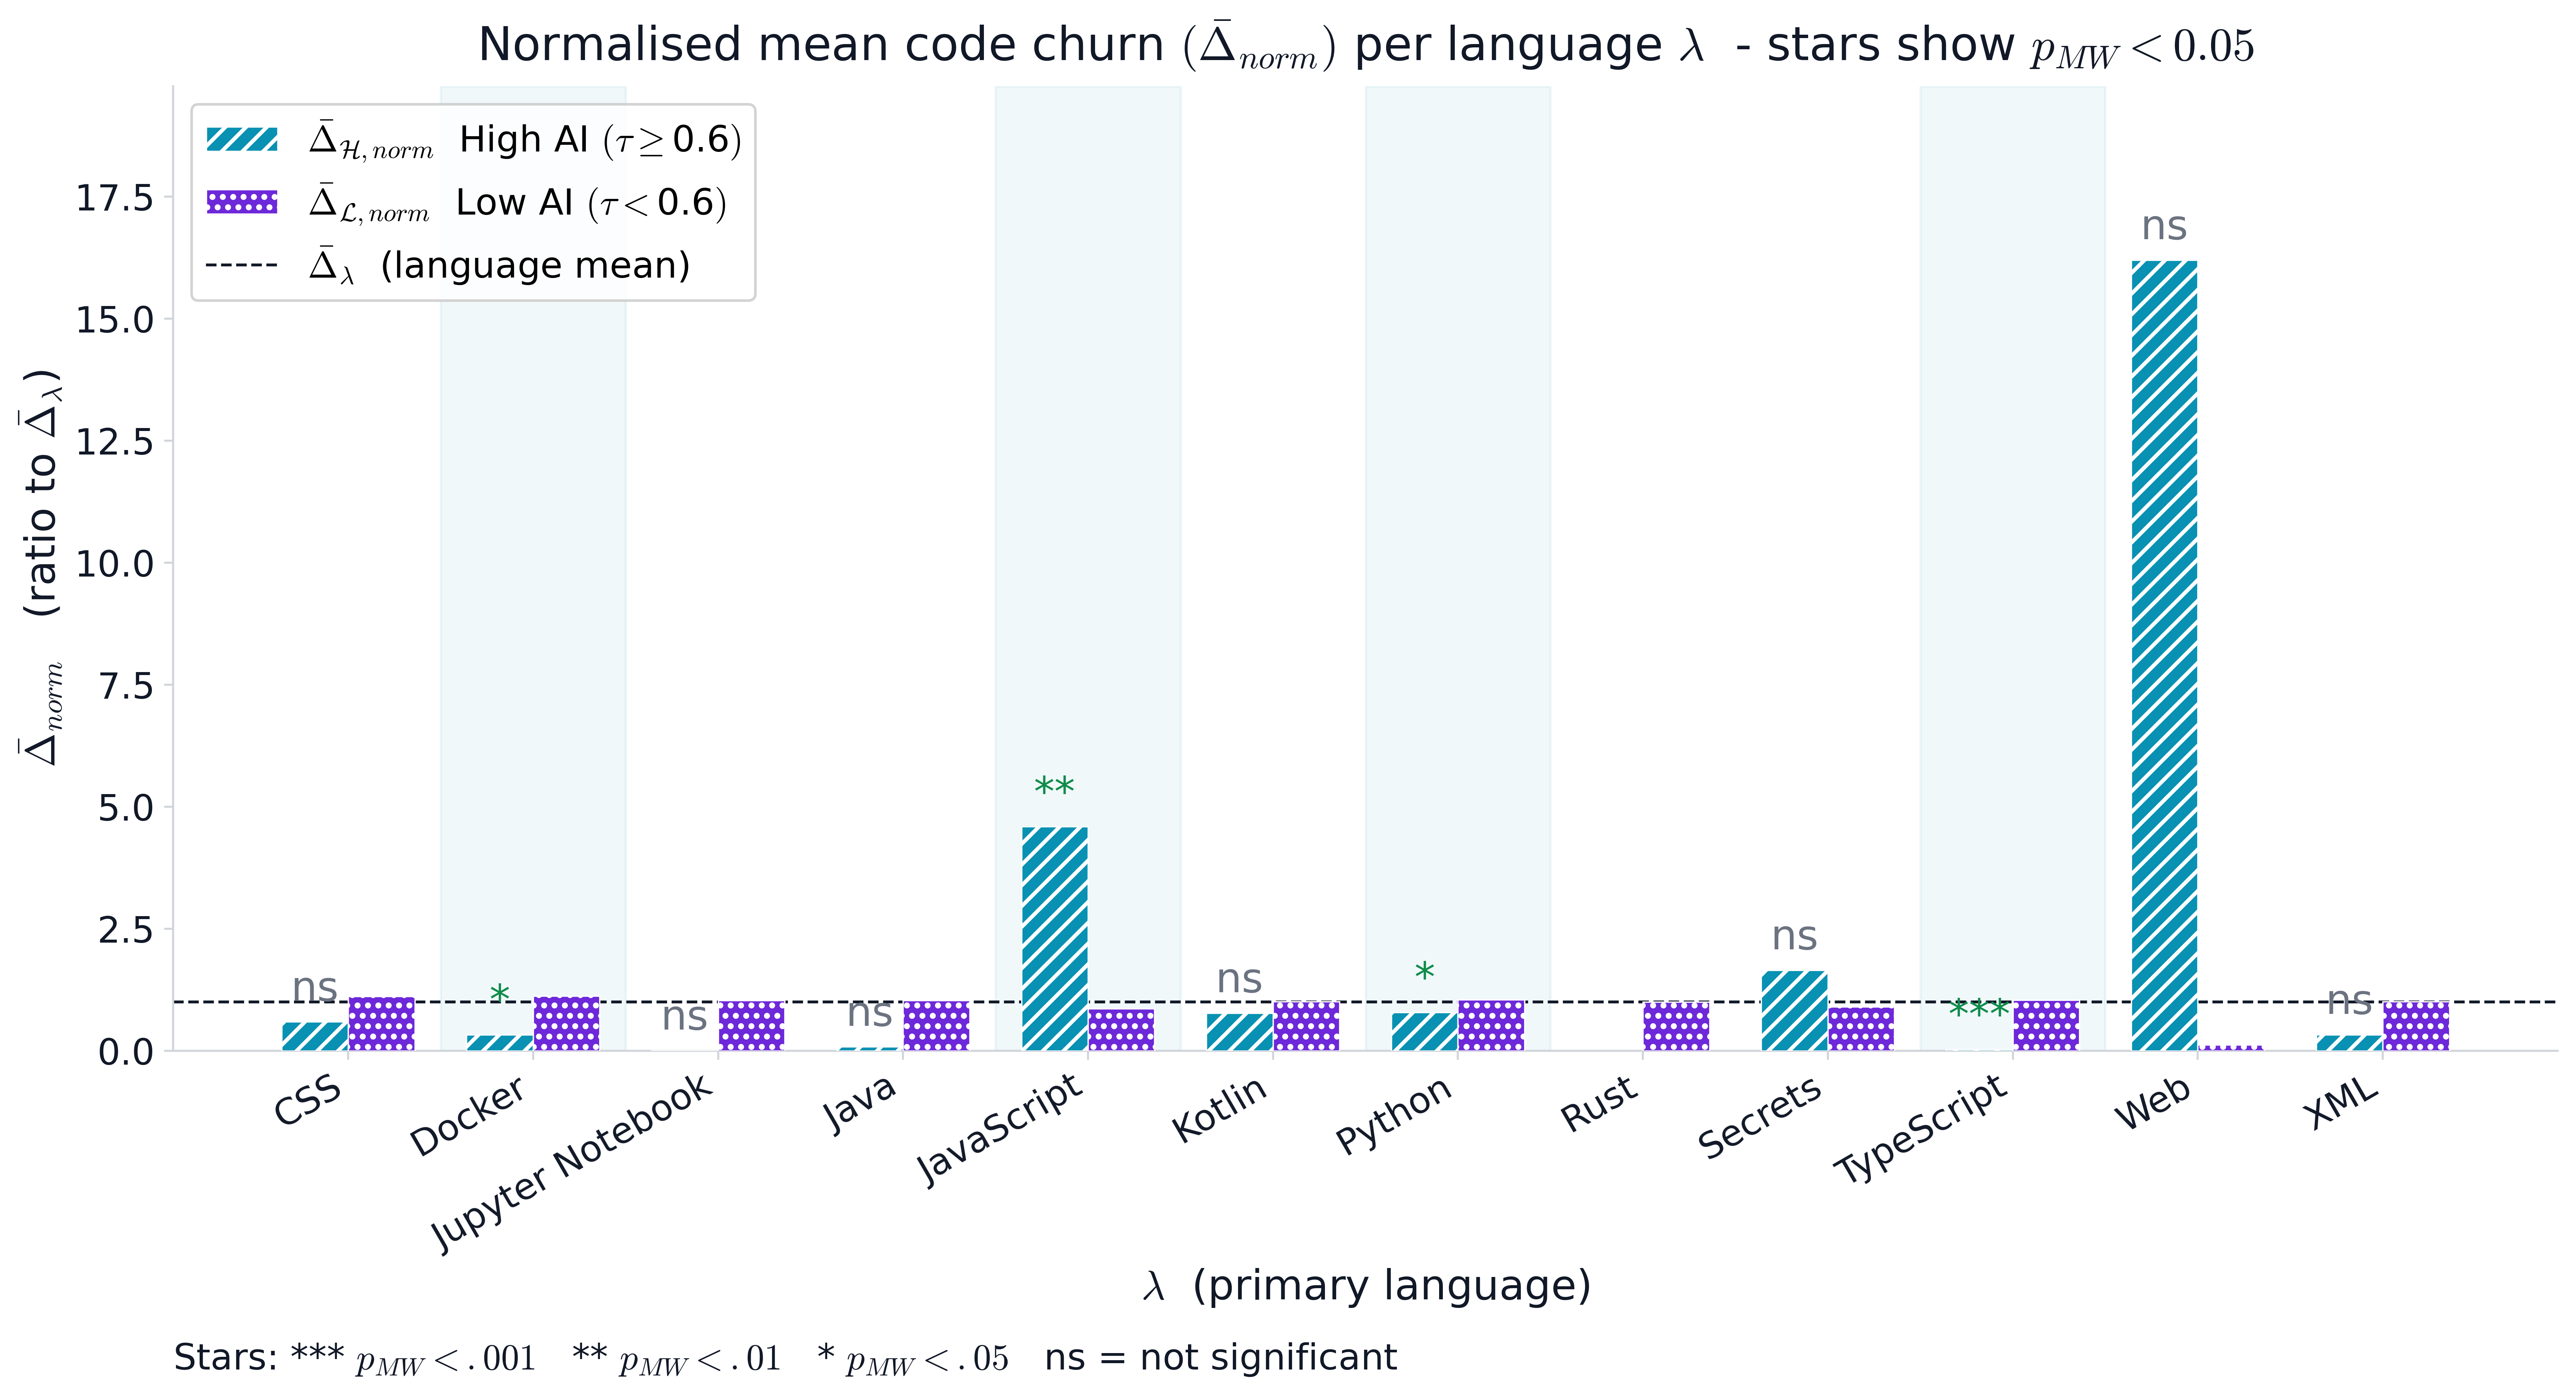

Saved to overleaf/H1_1_2.pdf


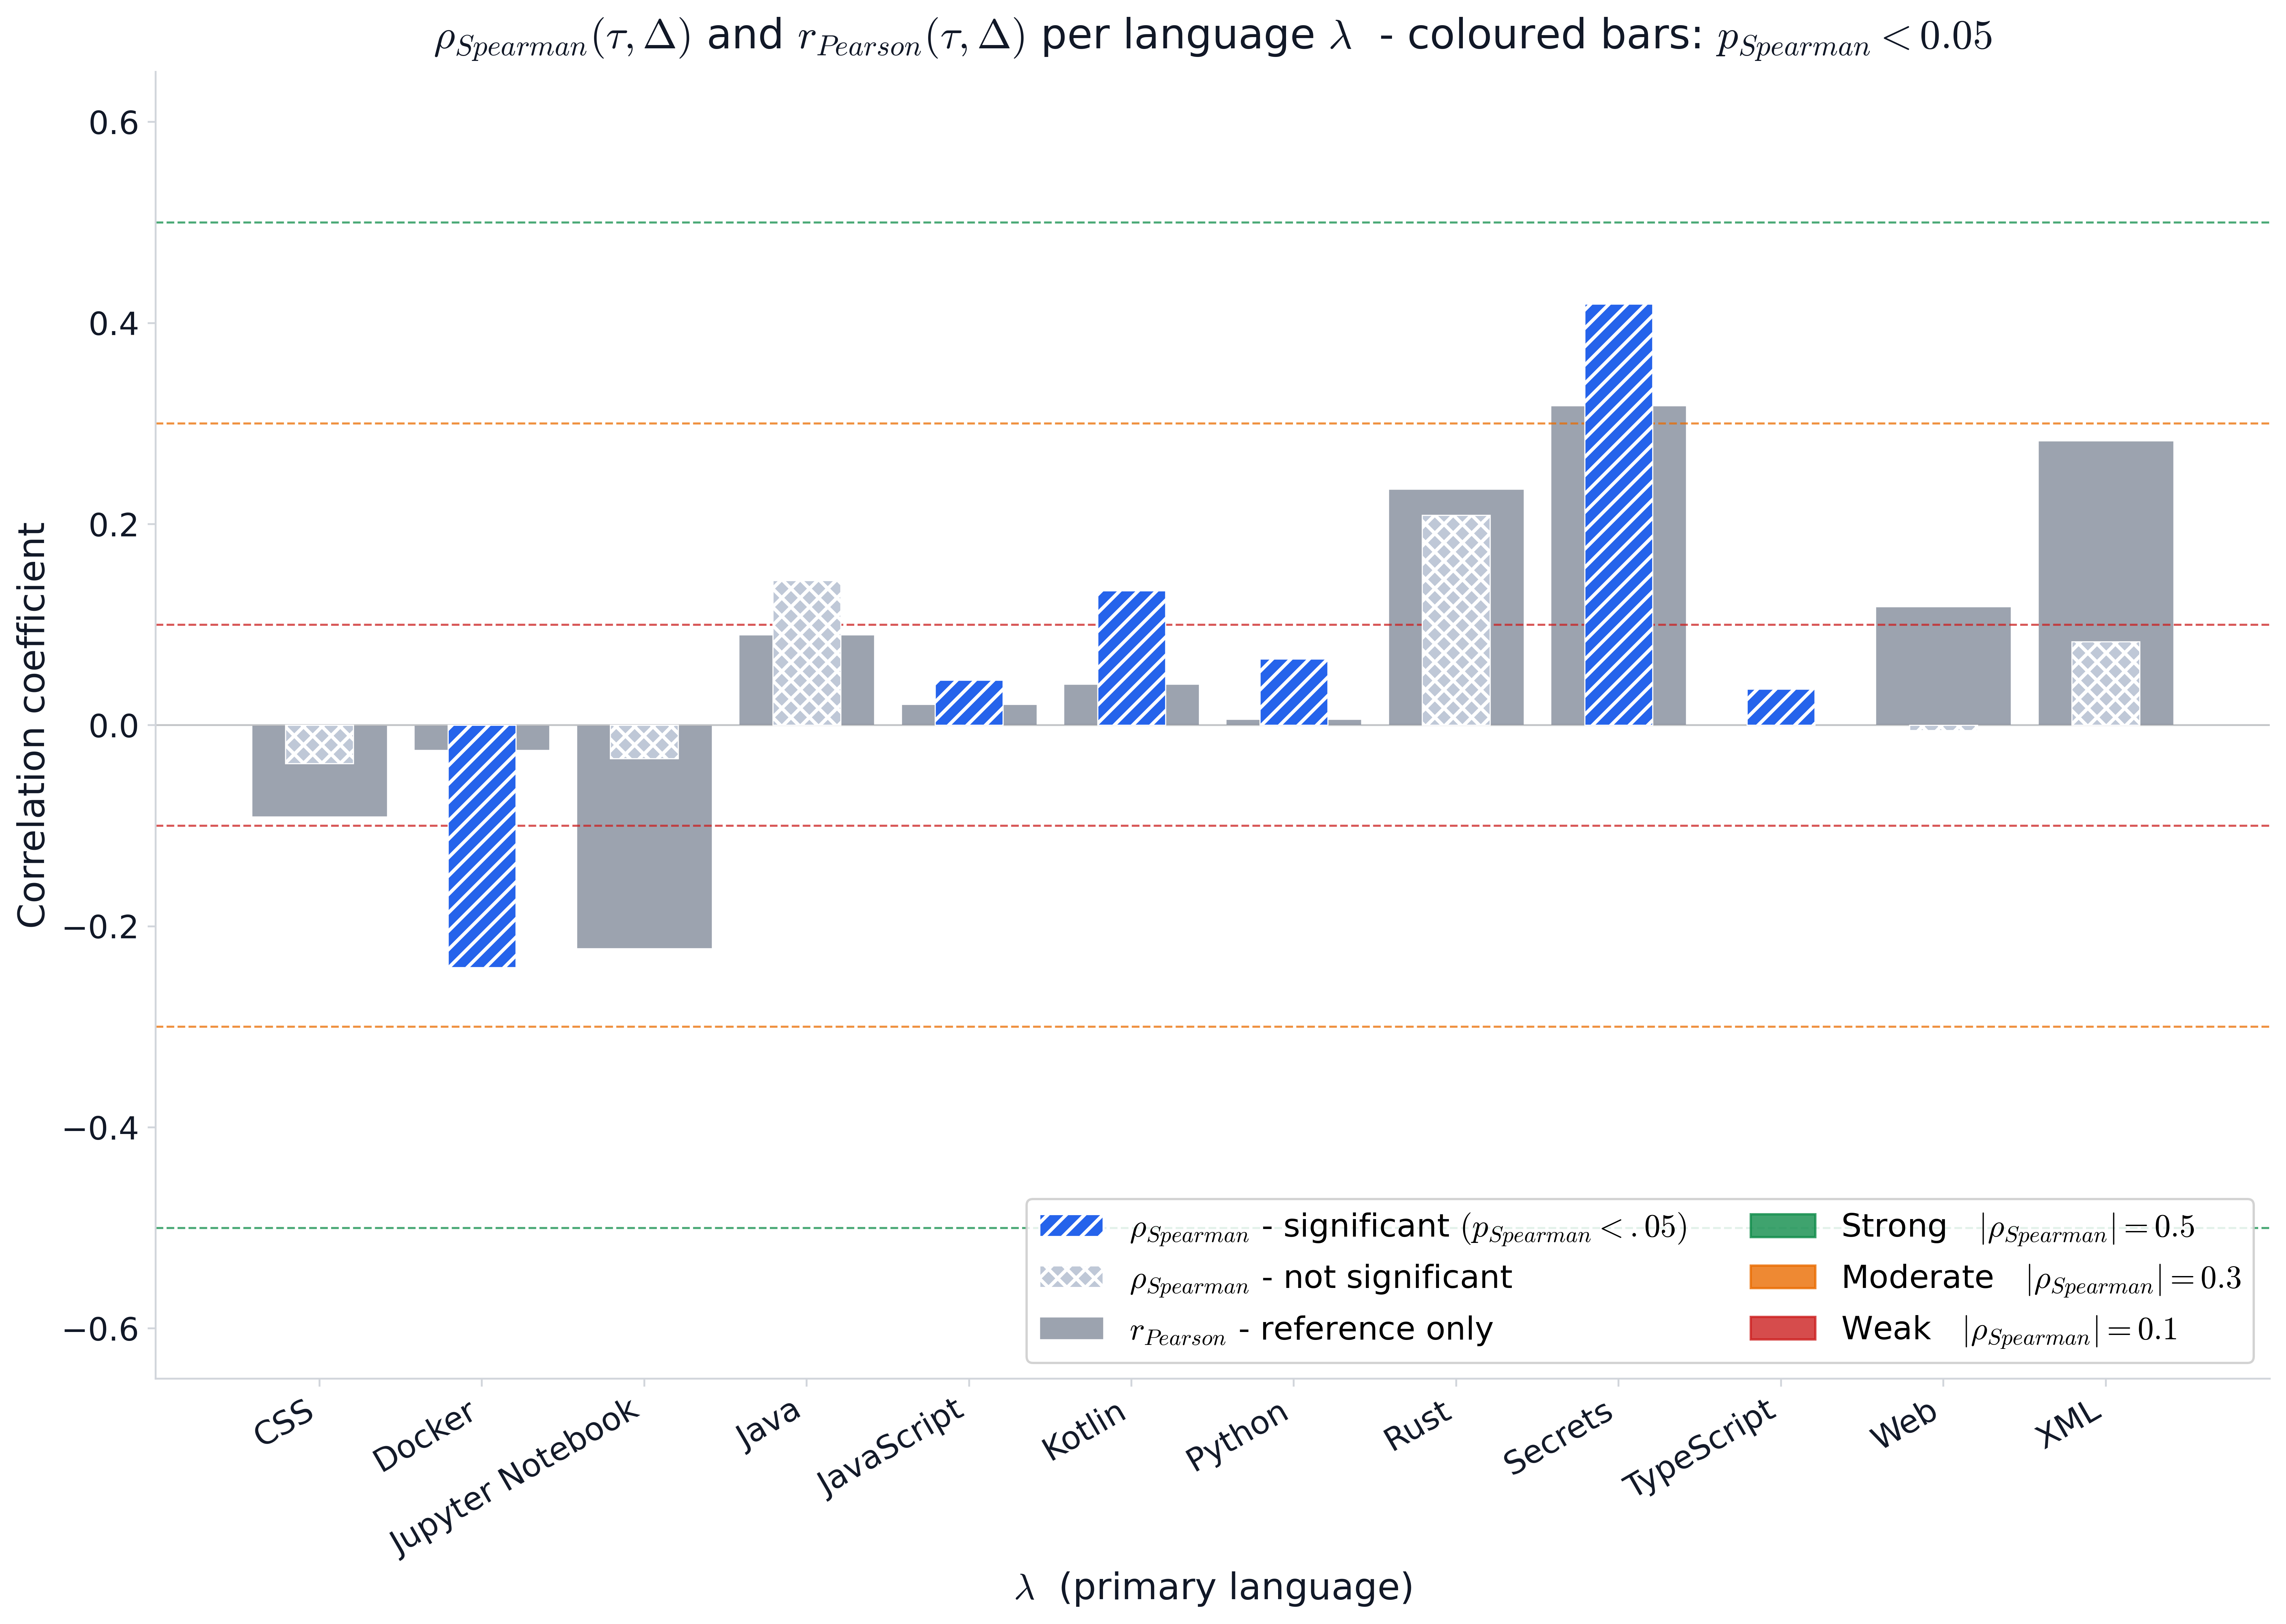

Saved to overleaf/H1_1_3.pdf


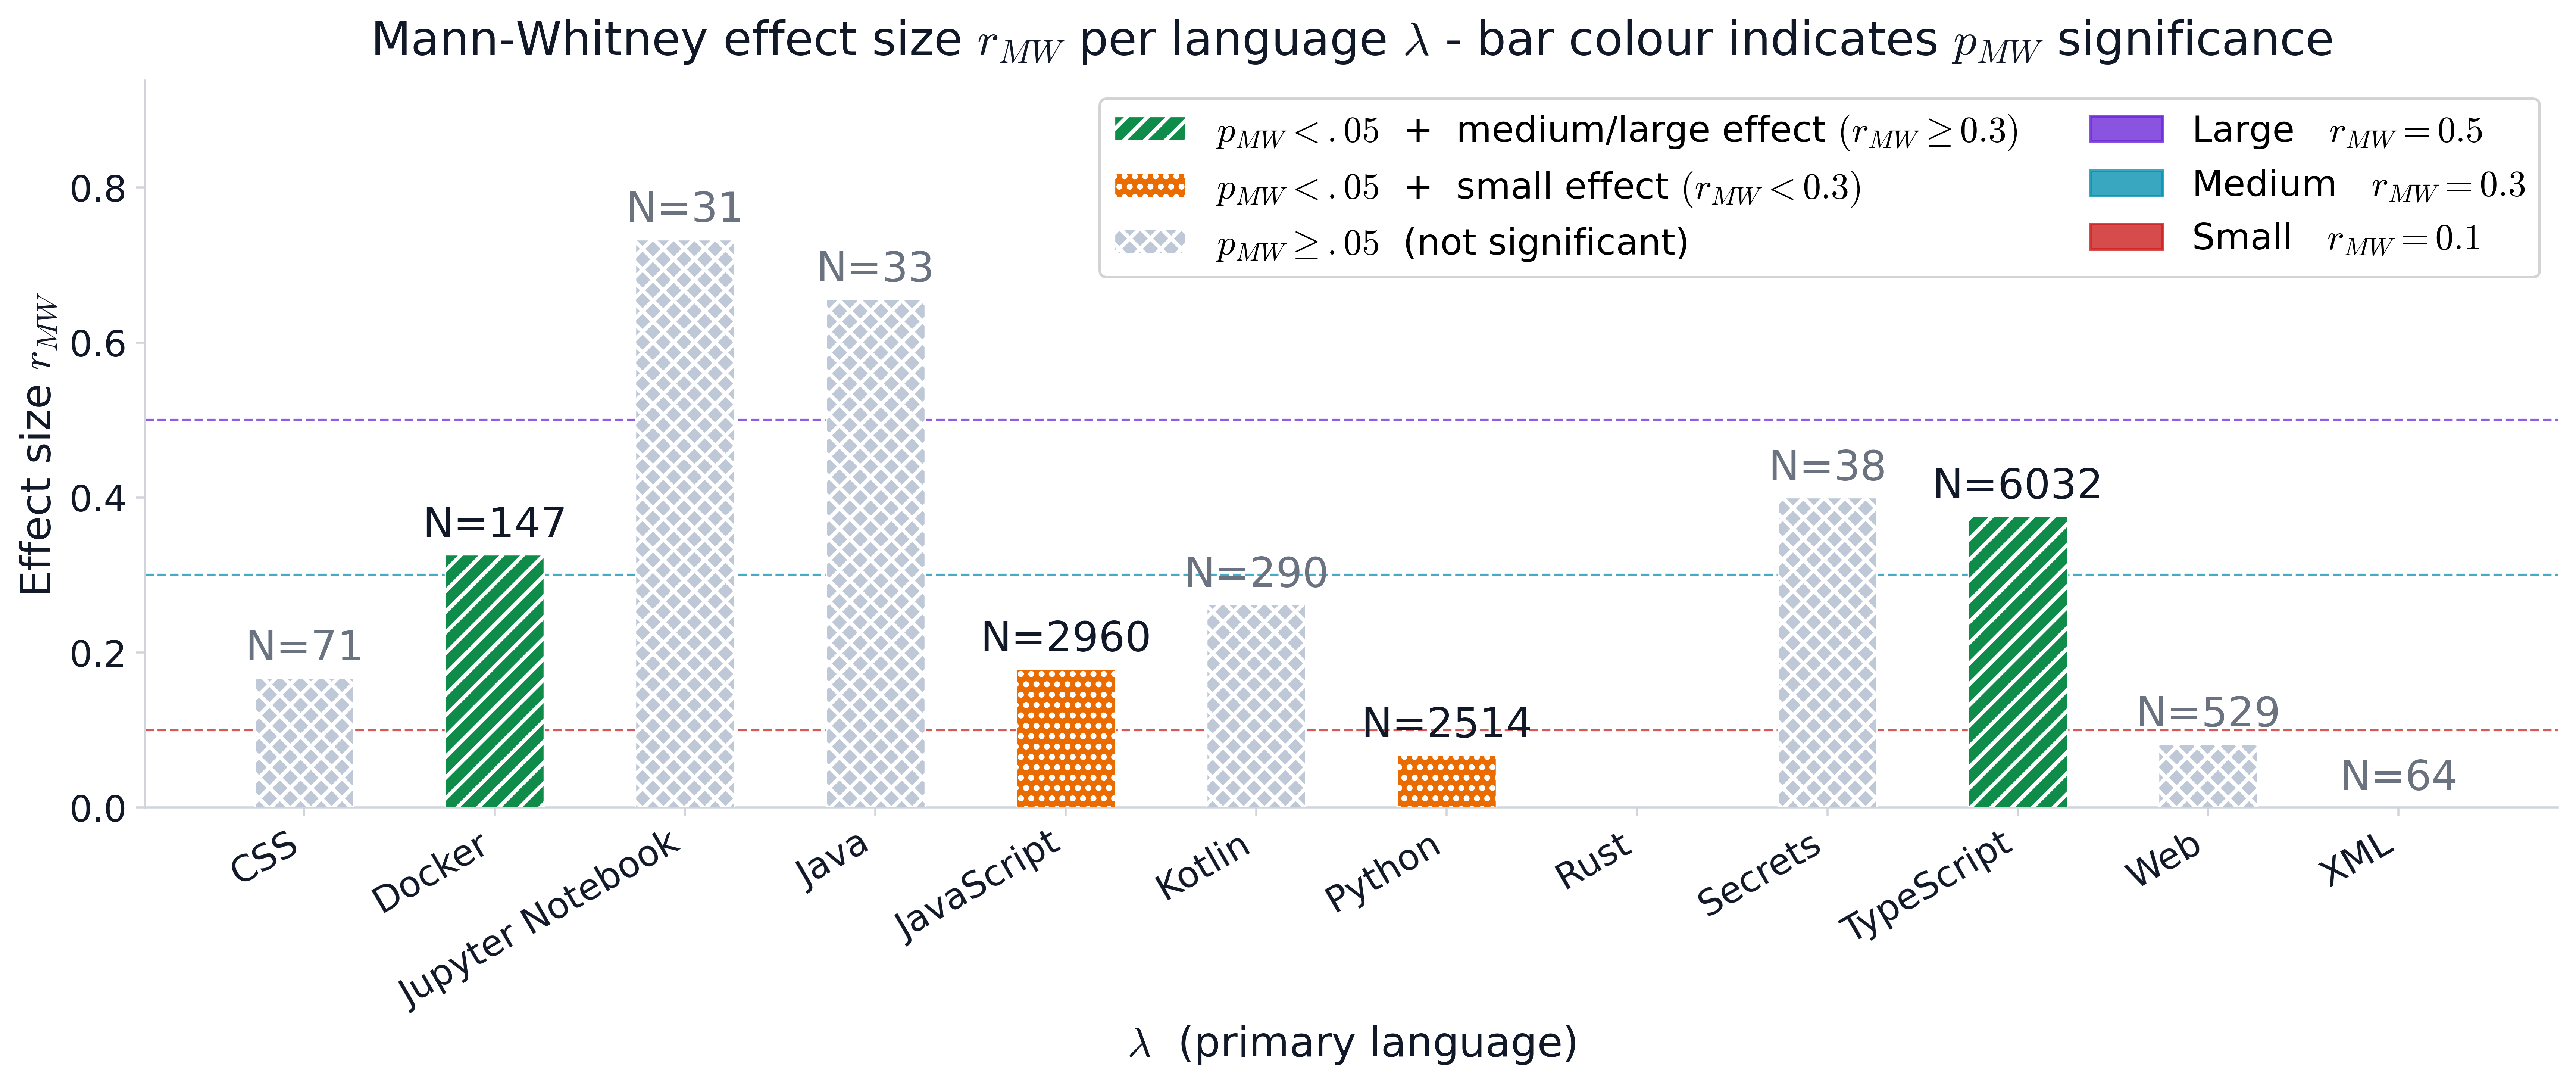

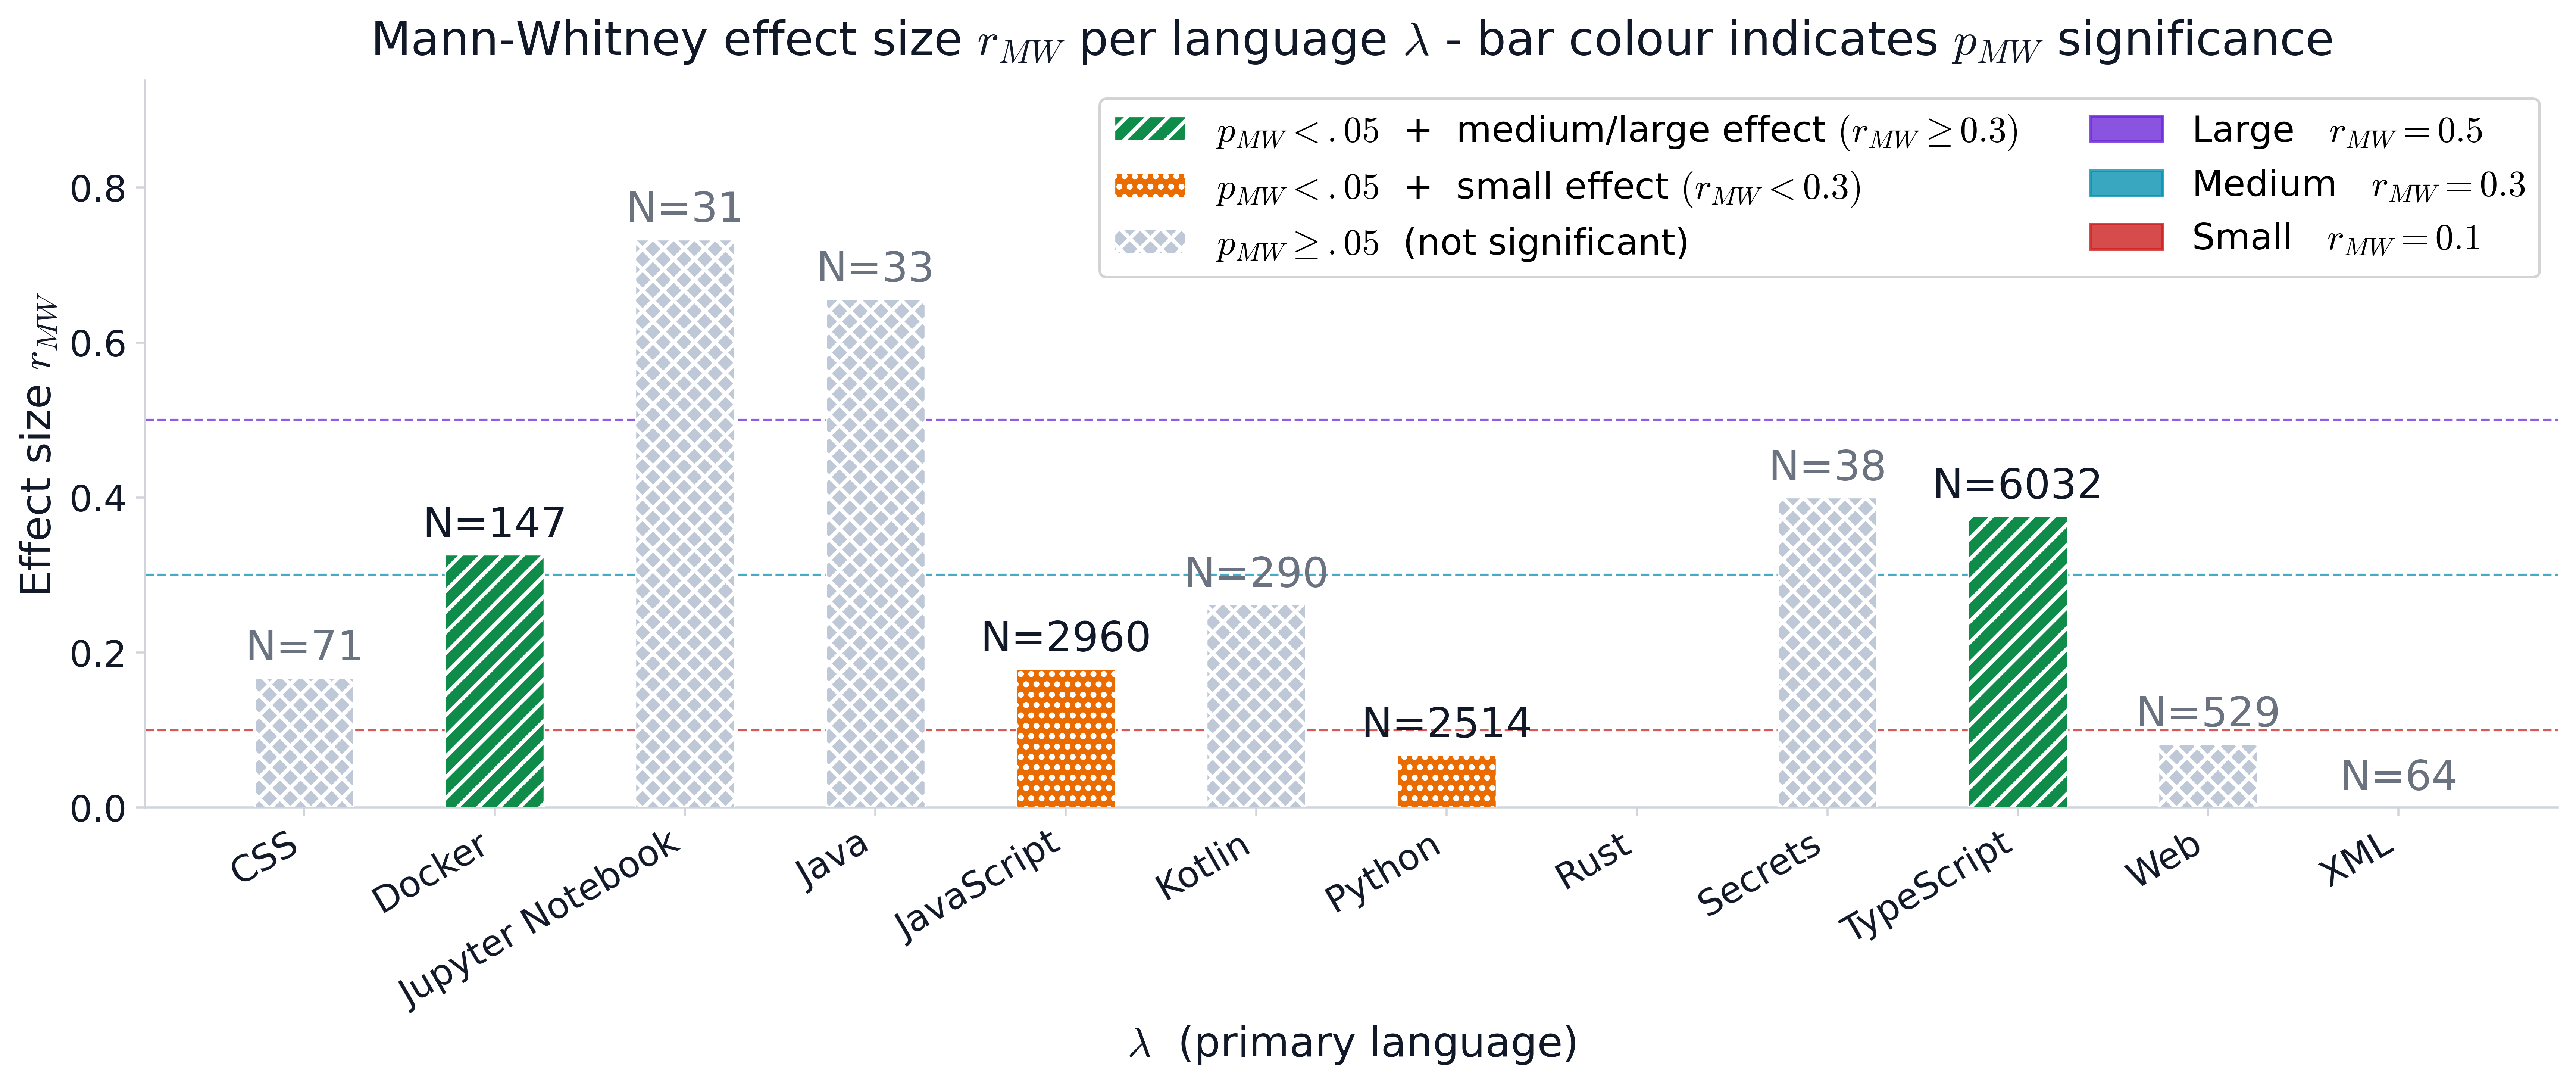

In [151]:
plot_h1_normalised_churn(results_df, high_threshold=0.6, save_path="overleaf/H1_1_1.pdf")
plot_h1_correlation(results_df, save_path="overleaf/H1_1_2.pdf")
plot_h1_effect_size(results_df, save_path="overleaf/H1_1_3.pdf")

In [95]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# How many projects in the high and low groups per language

threshold = 0.6

# for lang in results_df["Language"]:
#     lang_df = df[df["primary_language"] == lang].copy()
#     lang_df[ai_prob_col] = pd.to_numeric(lang_df[ai_prob_col], errors="coerce")
#     lang_df[size_col]    = pd.to_numeric(lang_df[size_col], errors="coerce")
#     lang_df = lang_df.dropna(subset=[ai_prob_col, size_col])

#     if len(lang_df) < 10:
#         continue

#     high_ai = lang_df[lang_df[ai_prob_col] >= threshold][size_col]
#     low_ai  = lang_df[lang_df[ai_prob_col] <  threshold][size_col]

#     print(f"{lang}: High AI n={len(high_ai)}, Low AI n={len(low_ai)}")
#     print("Percentage in High AI group: {:.1f}%".format(len(high_ai) / len(lang_df) * 100))

year_lang_df = df.copy()
year_lang_df["year"] = pd.to_datetime(year_lang_df["date"], utc=True).dt.year
year_lang_df["primary_language"] = year_lang_df["primary_language"].fillna("Unknown")
year_lang_df[ai_prob_col] = pd.to_numeric(year_lang_df[ai_prob_col], errors="coerce")

# Drop rows where ai_prob_col is NaN before grouping
year_lang_df = year_lang_df.dropna(subset=[ai_prob_col])

# Group by year and language
yearly_lang_distribution = (
    year_lang_df.groupby(["year", "primary_language"], group_keys=False)
    .apply(lambda g: pd.Series({
        "N": len(g),
        "high_ai_n": int((g[ai_prob_col] >= threshold).sum()),
        "low_ai_n": int((g[ai_prob_col] < threshold).sum()),
    }))
    .reset_index()
)

yearly_lang_distribution["% High AI"] = (
    yearly_lang_distribution["high_ai_n"] / yearly_lang_distribution["N"] * 100
).round(1)

# Sanity check — high + low should always equal N
assert (yearly_lang_distribution["high_ai_n"] + yearly_lang_distribution["low_ai_n"] == yearly_lang_distribution["N"]).all(), "Mismatch between high + low and N"

languages_of_interest = results_df["Language"].tolist()
yearly_lang_distribution = yearly_lang_distribution[
    yearly_lang_distribution["primary_language"].isin(languages_of_interest)
]


Languages included in heatmap: ['JavaScript', 'Web', 'Python', 'CSS', 'Docker', 'TypeScript', 'Java', 'Secrets', 'Kotlin', 'Rust', 'Jupyter Notebook', 'XML']


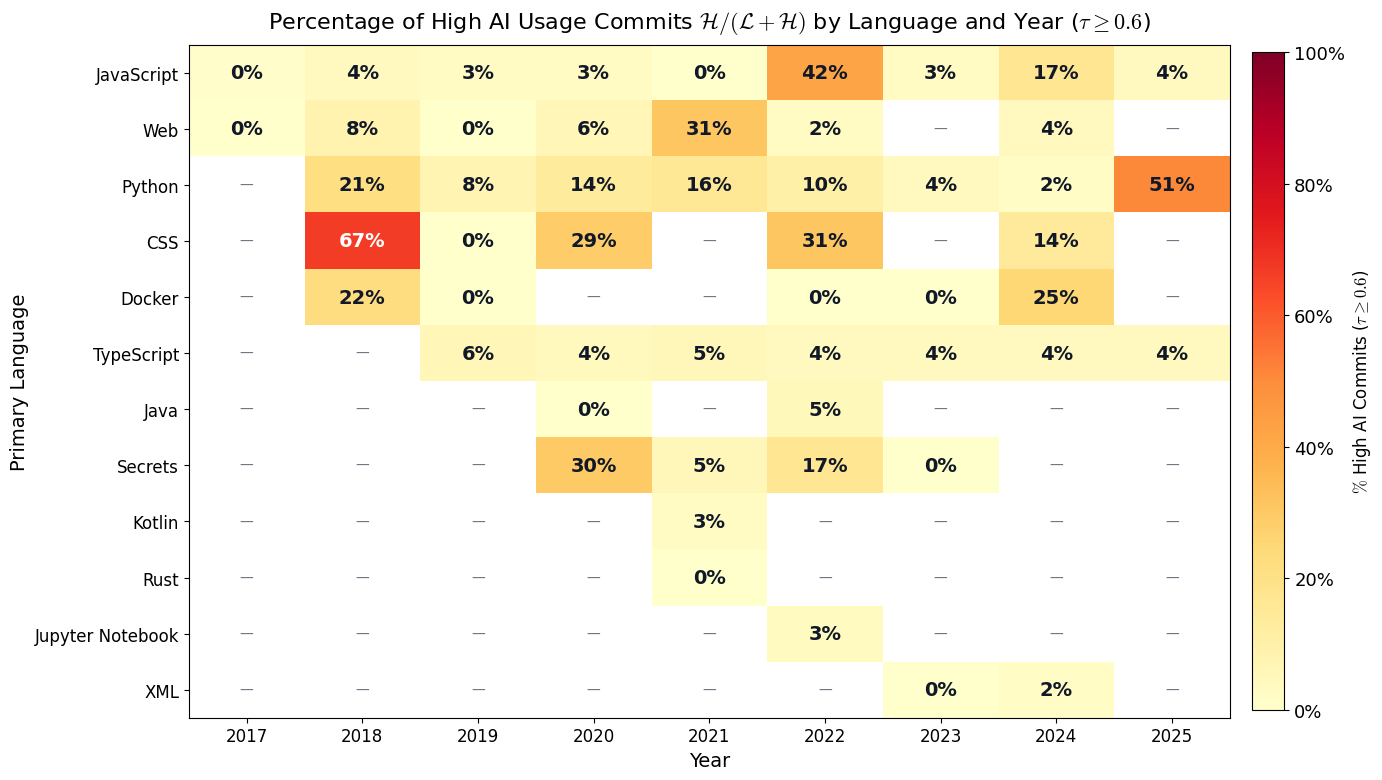

In [144]:
fig, ax = plt.subplots(figsize=(14, 8))
min_years = 1
valid_languages = (
    yearly_lang_distribution.groupby("primary_language")["year"]
    .count()
    .loc[lambda x: x >= min_years]
    .index.tolist()
)

plot_df = yearly_lang_distribution.copy()

years_sorted = sorted(plot_df["year"].unique())
language_order = [
    "js", 
    "web", 
    "py", 
    "css", 
    "docker",
    "ts", 
    "java", 
    "secrets", 
    "kotlin", 
    "rust", 
    "ipynb", 
    "xml"
]

langs_sorted = sorted(
    valid_languages, 
    key=lambda x: language_order.index(x.lower()) if x.lower() in language_order else len(language_order)
)

print("Languages included in heatmap:", [LANGUAGE_TO_LABEL.get(lang, lang) for lang in langs_sorted])
# Build pivot for heatmap
pivot = plot_df.pivot(index="primary_language", columns="year", values="% High AI").reindex(langs_sorted)

im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)

# Axes labels
ax.set_xticks(range(len(years_sorted)))
ax.set_xticklabels([str(int(y)) for y in years_sorted], fontsize=12)
ax.set_yticks(range(len(langs_sorted)))
ax.set_yticklabels([LANGUAGE_TO_LABEL.get(lang, lang) for lang in langs_sorted], fontsize=12)

# Annotate each cell with the value
for row_i, lang in enumerate(langs_sorted):
    for col_i, year in enumerate(years_sorted):
        val = pivot.loc[lang, year] if year in pivot.columns else float("nan")
        if not pd.isna(val):
            text_color = "white" if val > 55 else C_TEXT
            ax.text(col_i, row_i, f"{val:.0f}%",
                    ha="center", va="center", fontsize=14,
                    color=text_color, fontweight="bold")
        else:
            ax.text(col_i, row_i, "—",
                    ha="center", va="center", fontsize=10, color=C_TEXT_NS)

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label(r"$\%$ High AI Commits ($\tau \geq 0.6$)", fontsize=12)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v)}%"))

ax.set_title(r"Percentage of High AI Usage Commits $\mathcal{H} / (\mathcal{L} + \mathcal{H})$ by Language and Year ($\tau \geq 0.6$)",
             fontsize=16, pad=12)
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Primary Language", fontsize=14)

plt.tight_layout()
plt.savefig("overleaf/H1_1_0.pdf", format="pdf")
plt.show()


In [98]:
from itertools import groupby as itertools_groupby

filtered = (yearly_lang_distribution[["year", "primary_language", "N", "high_ai_n", "low_ai_n", "% High AI"]]
            .sort_values(["primary_language", "year"]))

languages = filtered["primary_language"].unique()

lines = []
lines.append(r"\begin{landscape}")
lines.append(r"\begin{table}[H]")
lines.append(r"\centering")
lines.append(r"\footnotesize")
lines.append(r"\begin{tabular}{llrrrr}")
lines.append(r"\toprule")
lines.append(r"\textbf{Language} & \textbf{Year} & \textbf{N} & \textbf{High AI ($n$)} & \textbf{Low AI ($n$)} & \textbf{\% High AI} \\")
lines.append(r"\midrule")

for i, lang in enumerate(languages):
    lang_rows = filtered[filtered["primary_language"] == lang]
    first = True
    for _, row in lang_rows.iterrows():
        lang_cell = r"\textit{" + lang + r"}" if first else ""
        lines.append(f"{lang_cell} & {int(row['year'])} & {int(row['N'])} & {int(row['high_ai_n'])} & {int(row['low_ai_n'])} & {row['% High AI']:.1f}\\% \\\\")
        first = False
    # Add midrule between languages, not after the last one
    if i < len(languages) - 1:
        lines.append(r"\midrule")

lines.append(r"\bottomrule")
lines.append(r"\end{tabular}")
lines.append(r"\caption{Distribution of High and Low AI usage groups per primary language and year. High AI is defined as $\tau \geq " + str(threshold) + r"$.}")
lines.append(r"\label{tab:yearly_lang_ai_distribution}")
lines.append(r"\end{table}")
lines.append(r"\end{landscape}")

print("\n".join(lines))

\begin{landscape}
\begin{table}[H]
\centering
\footnotesize
\begin{tabular}{llrrrr}
\toprule
\textbf{Language} & \textbf{Year} & \textbf{N} & \textbf{High AI ($n$)} & \textbf{Low AI ($n$)} & \textbf{\% High AI} \\
\midrule
\textit{css} & 2018 & 3 & 2 & 1 & 66.7\% \\
 & 2019 & 3 & 0 & 3 & 0.0\% \\
 & 2020 & 14 & 4 & 10 & 28.6\% \\
 & 2022 & 16 & 5 & 11 & 31.2\% \\
 & 2024 & 35 & 5 & 30 & 14.3\% \\
\midrule
\textit{docker} & 2018 & 82 & 18 & 64 & 22.0\% \\
 & 2019 & 3 & 0 & 3 & 0.0\% \\
 & 2022 & 16 & 0 & 16 & 0.0\% \\
 & 2023 & 26 & 0 & 26 & 0.0\% \\
 & 2024 & 20 & 5 & 15 & 25.0\% \\
\midrule
\textit{ipynb} & 2022 & 31 & 1 & 30 & 3.2\% \\
\midrule
\textit{java} & 2020 & 13 & 0 & 13 & 0.0\% \\
 & 2022 & 20 & 1 & 19 & 5.0\% \\
\midrule
\textit{js} & 2017 & 239 & 1 & 238 & 0.4\% \\
 & 2018 & 908 & 35 & 873 & 3.9\% \\
 & 2019 & 350 & 10 & 340 & 2.9\% \\
 & 2020 & 1080 & 30 & 1050 & 2.8\% \\
 & 2021 & 6 & 0 & 6 & 0.0\% \\
 & 2022 & 48 & 20 & 28 & 41.7\% \\
 & 2023 & 100 & 3 & 97 & 3.0\% \\
 

/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_78943/135578030.py:37: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  mw_u_high_ai,   mw_p   = stats.mannwhitneyu(n1, n2, alternative='two-sided')


Language    N  Median contribution (High AI)  Median contribution (Low AI)  Mean contribution (High AI)  Mean contribution (Low AI)  Mean contribution (High AI, norm.)  Mean contribution (Low AI, norm.)  U(contribution|ai_group)  U(contribution|~ai_group)  p_mw(contribution|ai_group)  r_mw(contribution|ai_group)  r_pearson(contribution~ai_prob)  p_pearson(contribution~ai_prob)  r_spearman(contribution~ai_prob)  p_spearman(contribution~ai_prob) Normal? p_sw_high_ai  p_sw_low_ai  high_ai_n  low_ai_n
     css   51                        12.5000                       22.0000                      55.2000                    116.1220                              0.5300                             1.1150                  174.5000                   235.5000                       0.4752                       0.1490                          -0.0330                           0.8175                            0.0090                            0.9484      No       0.0003       0.0000         10     

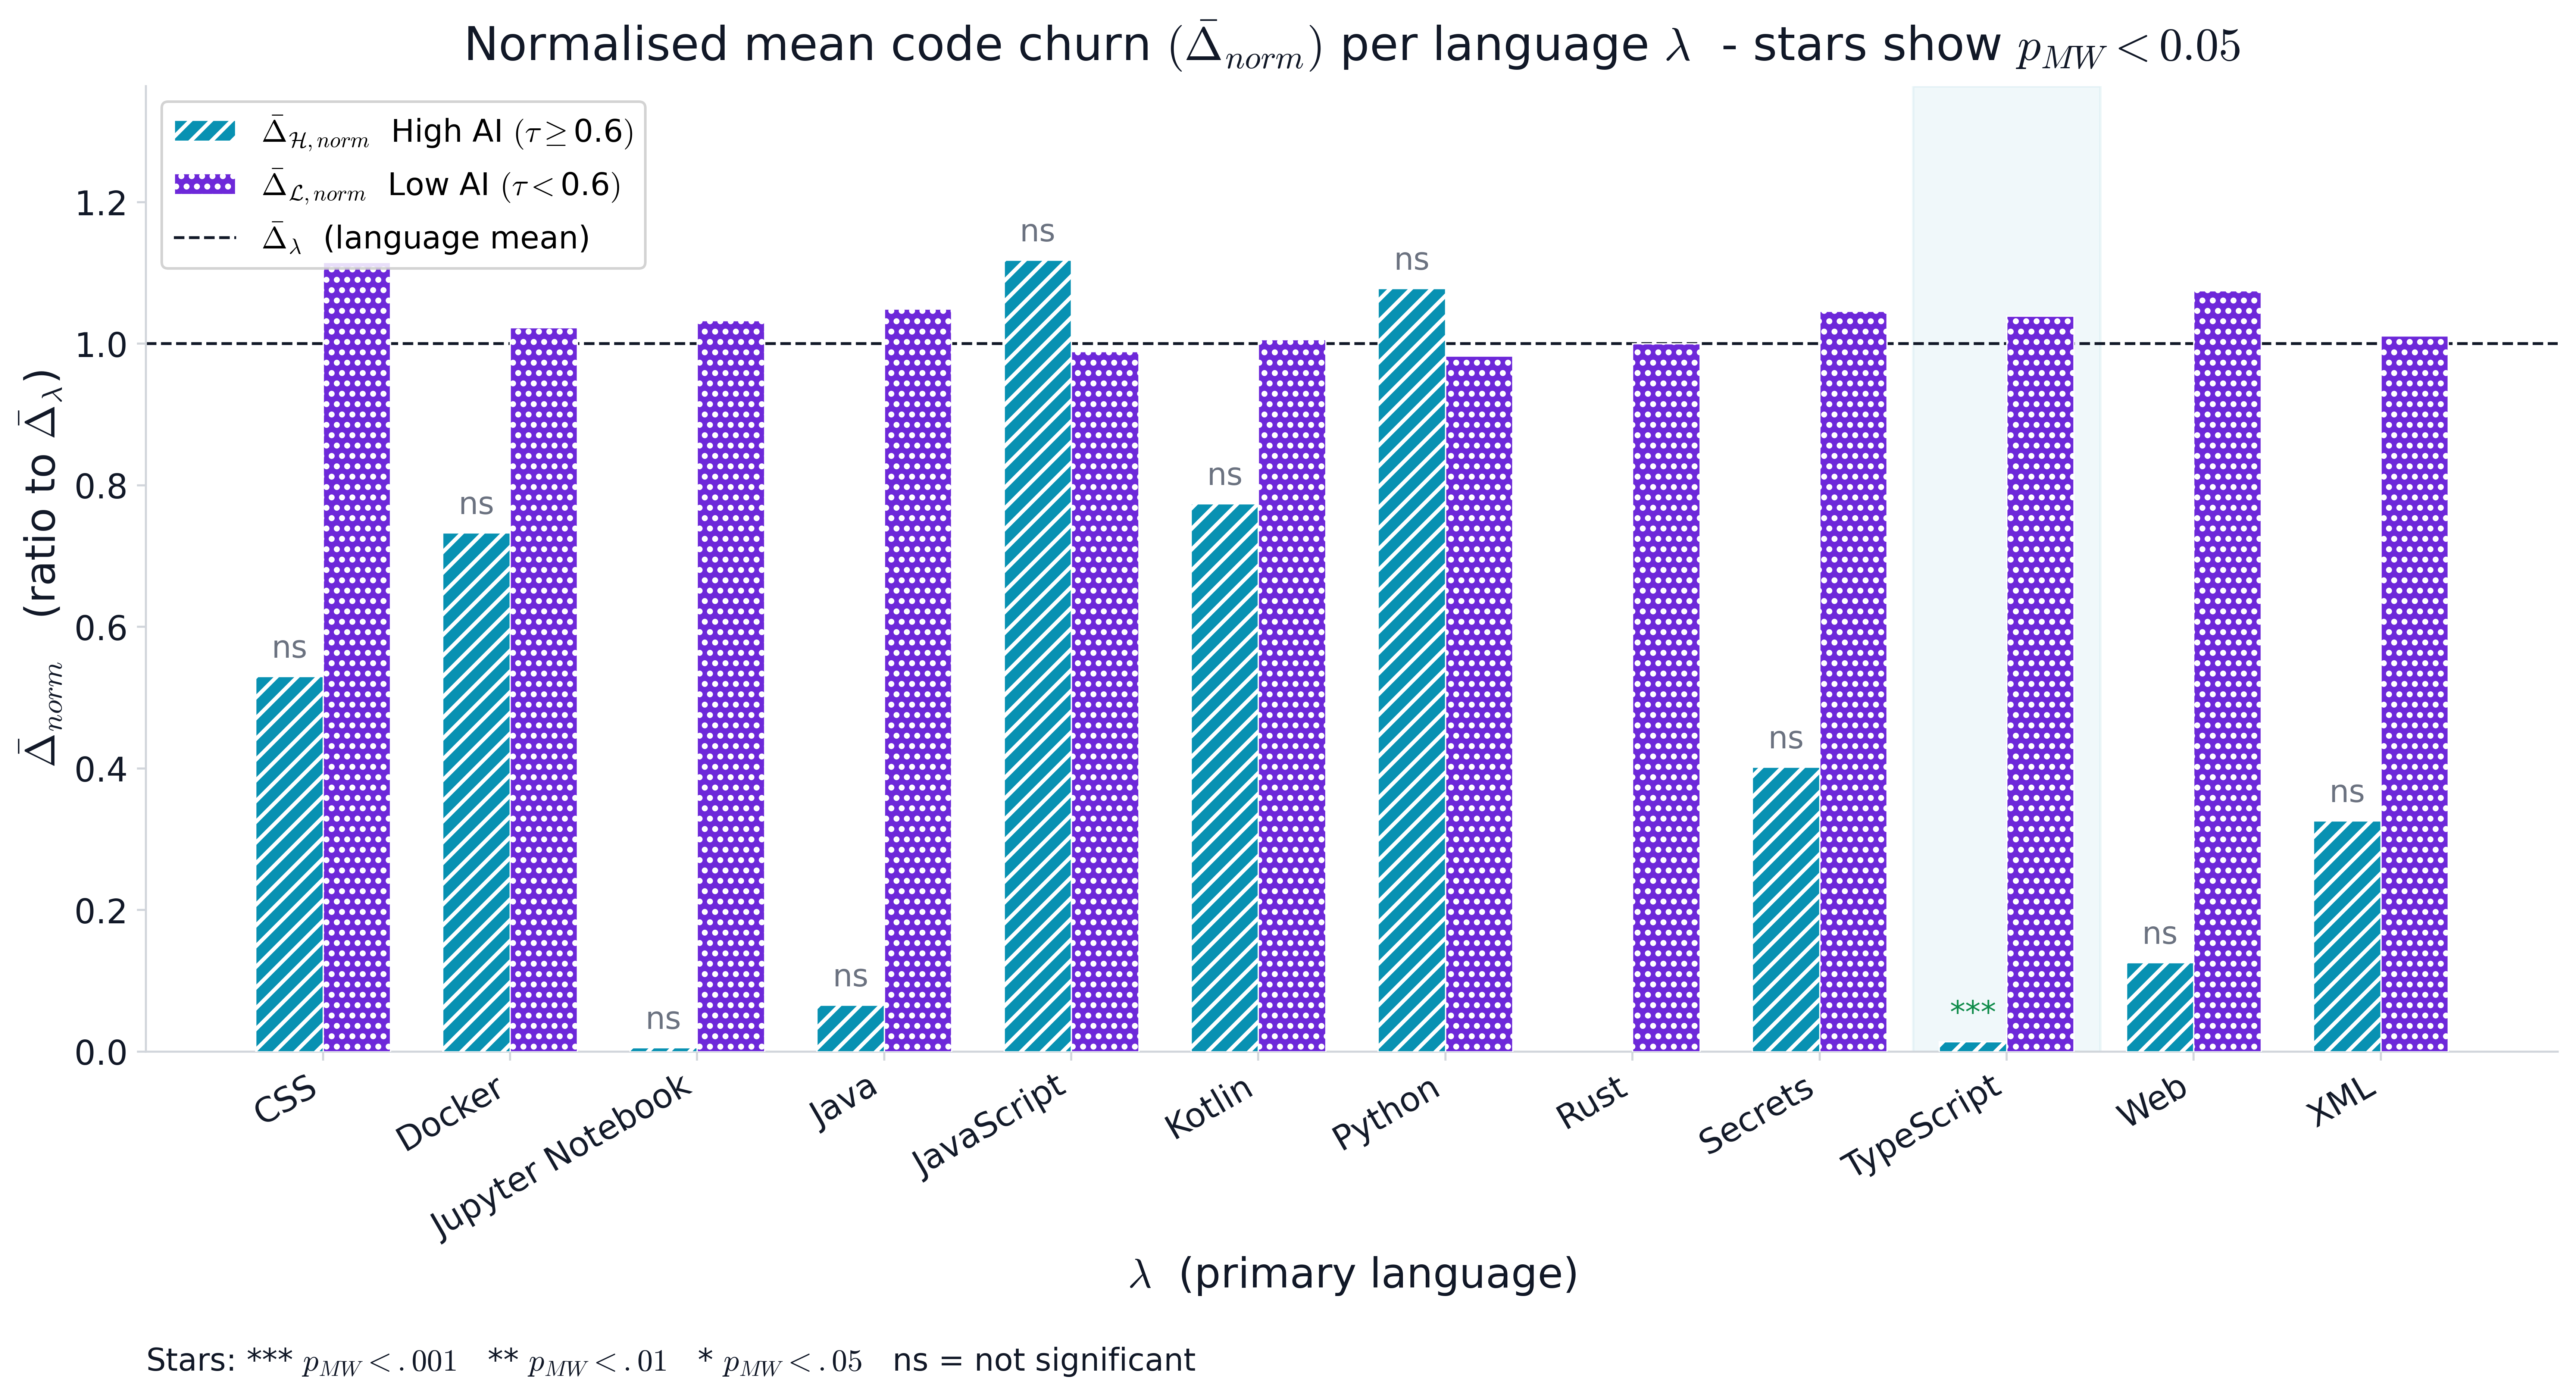

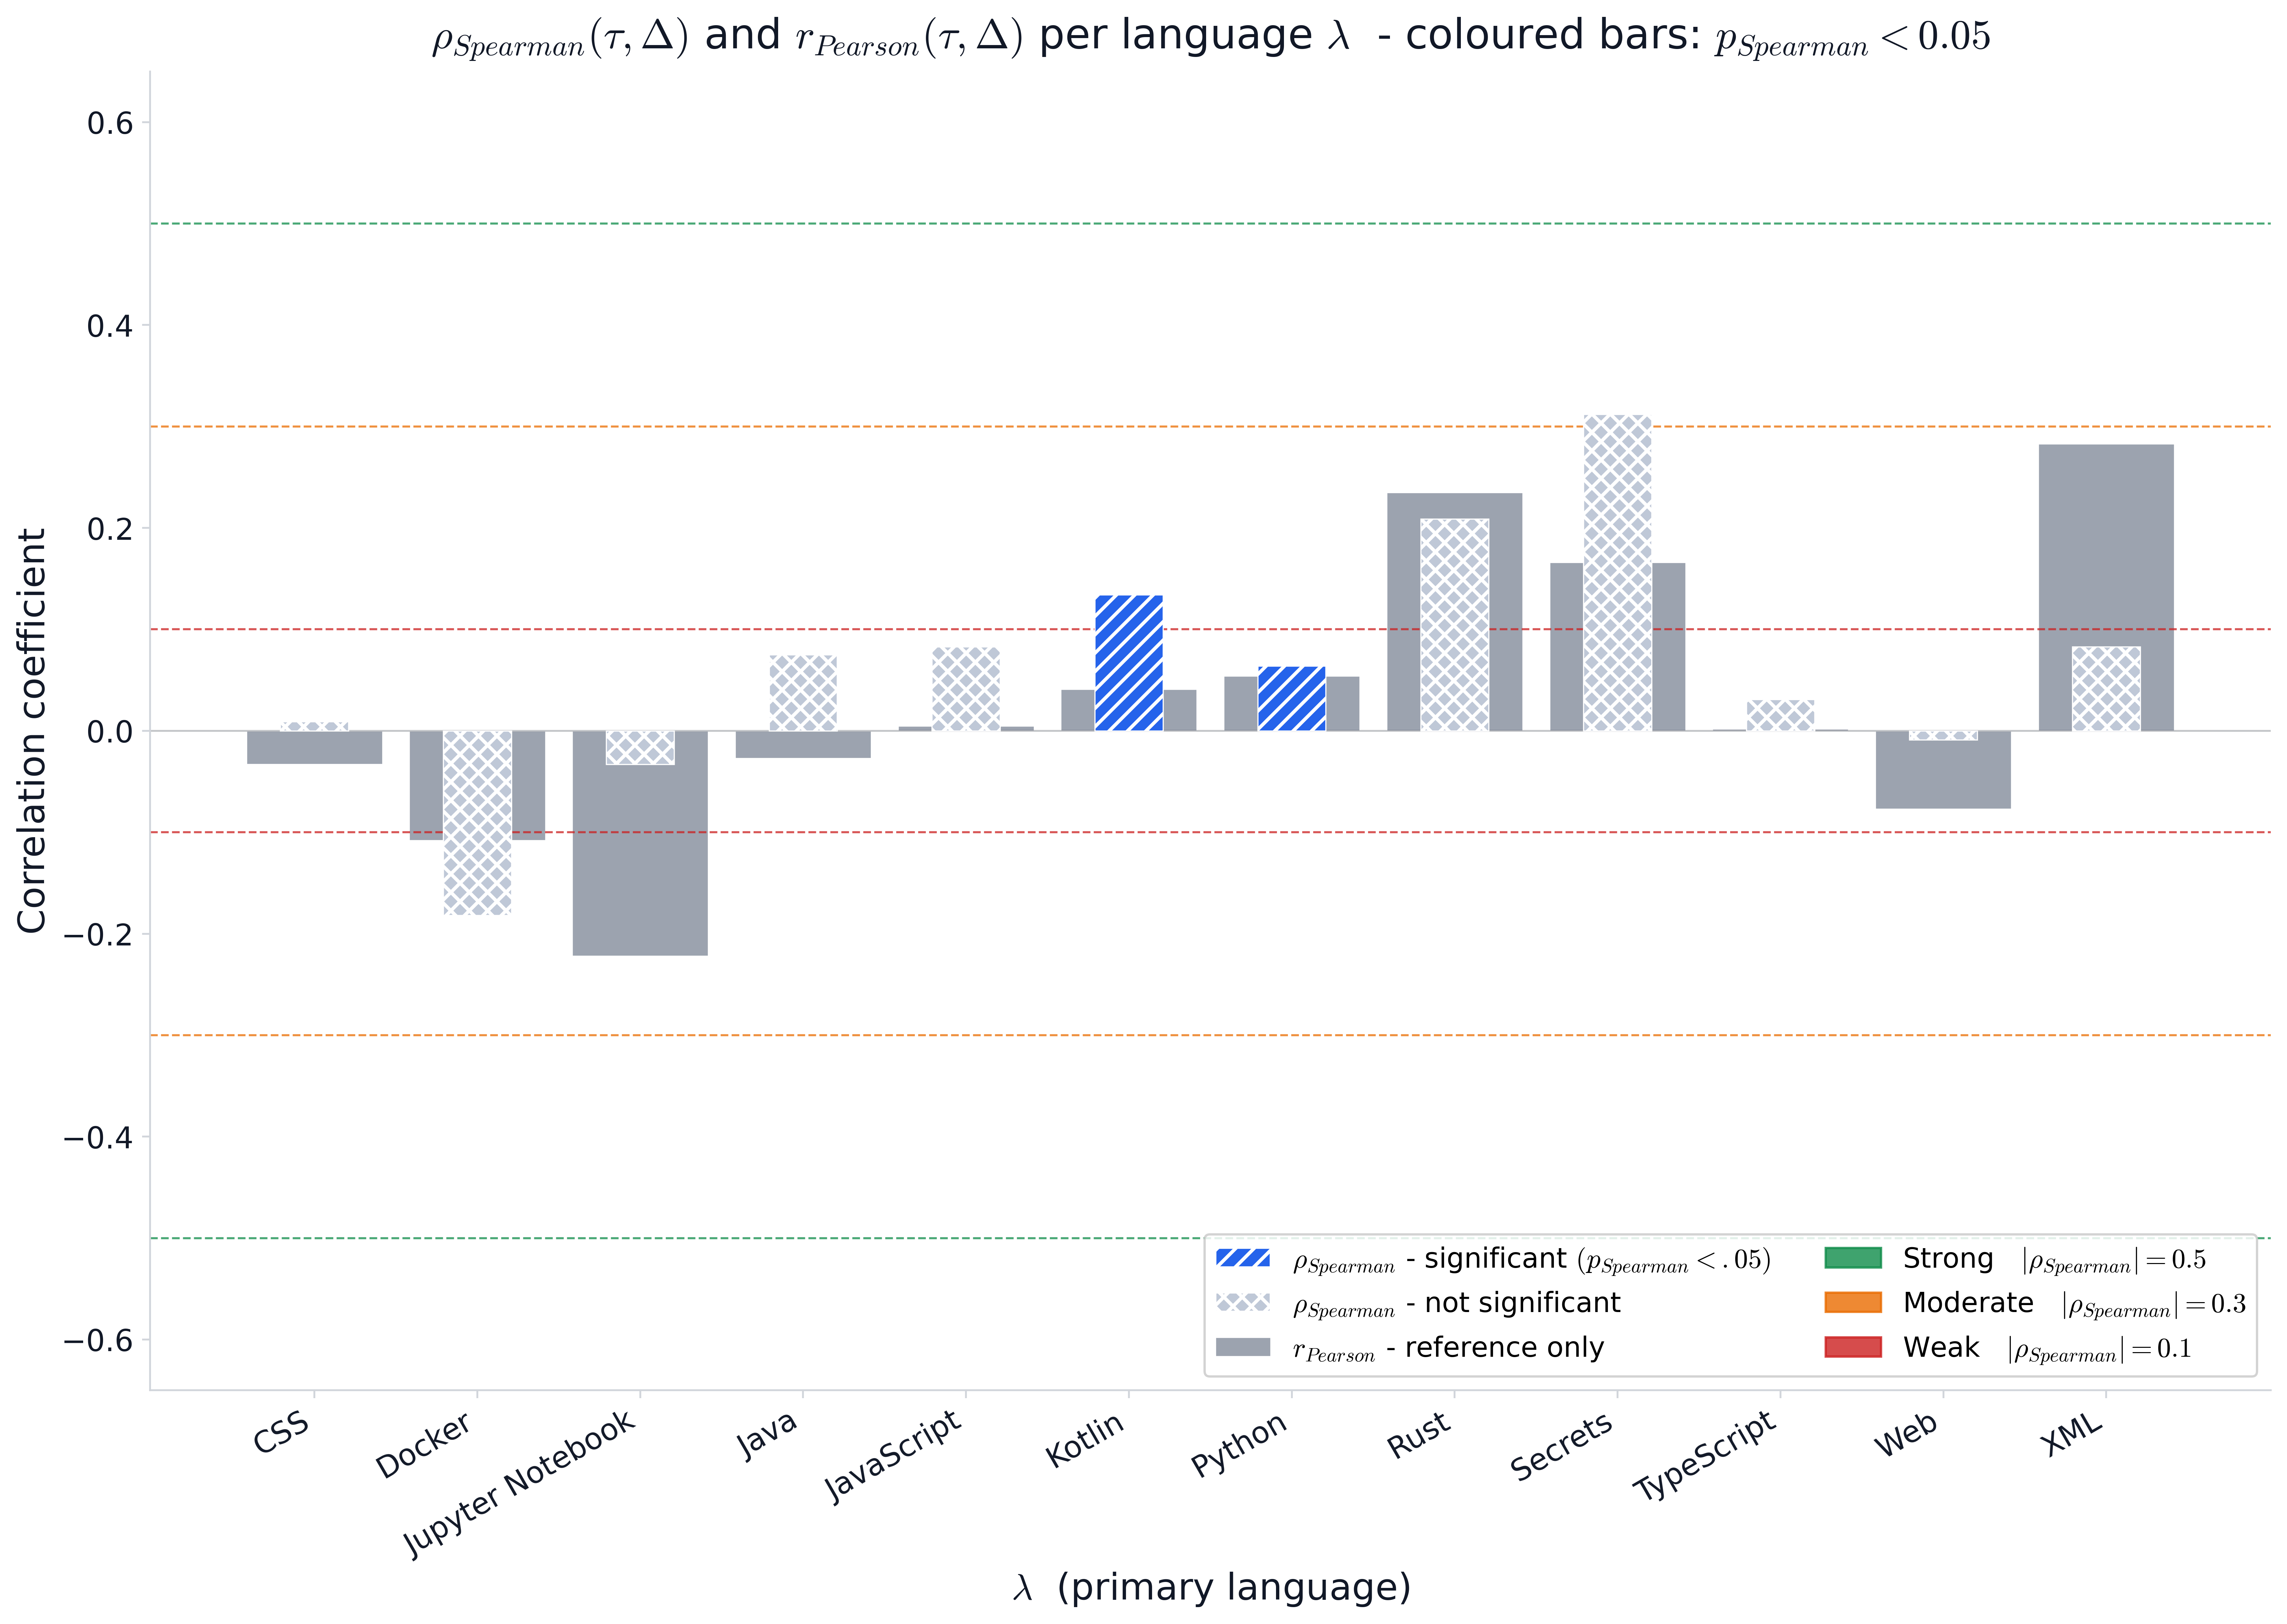

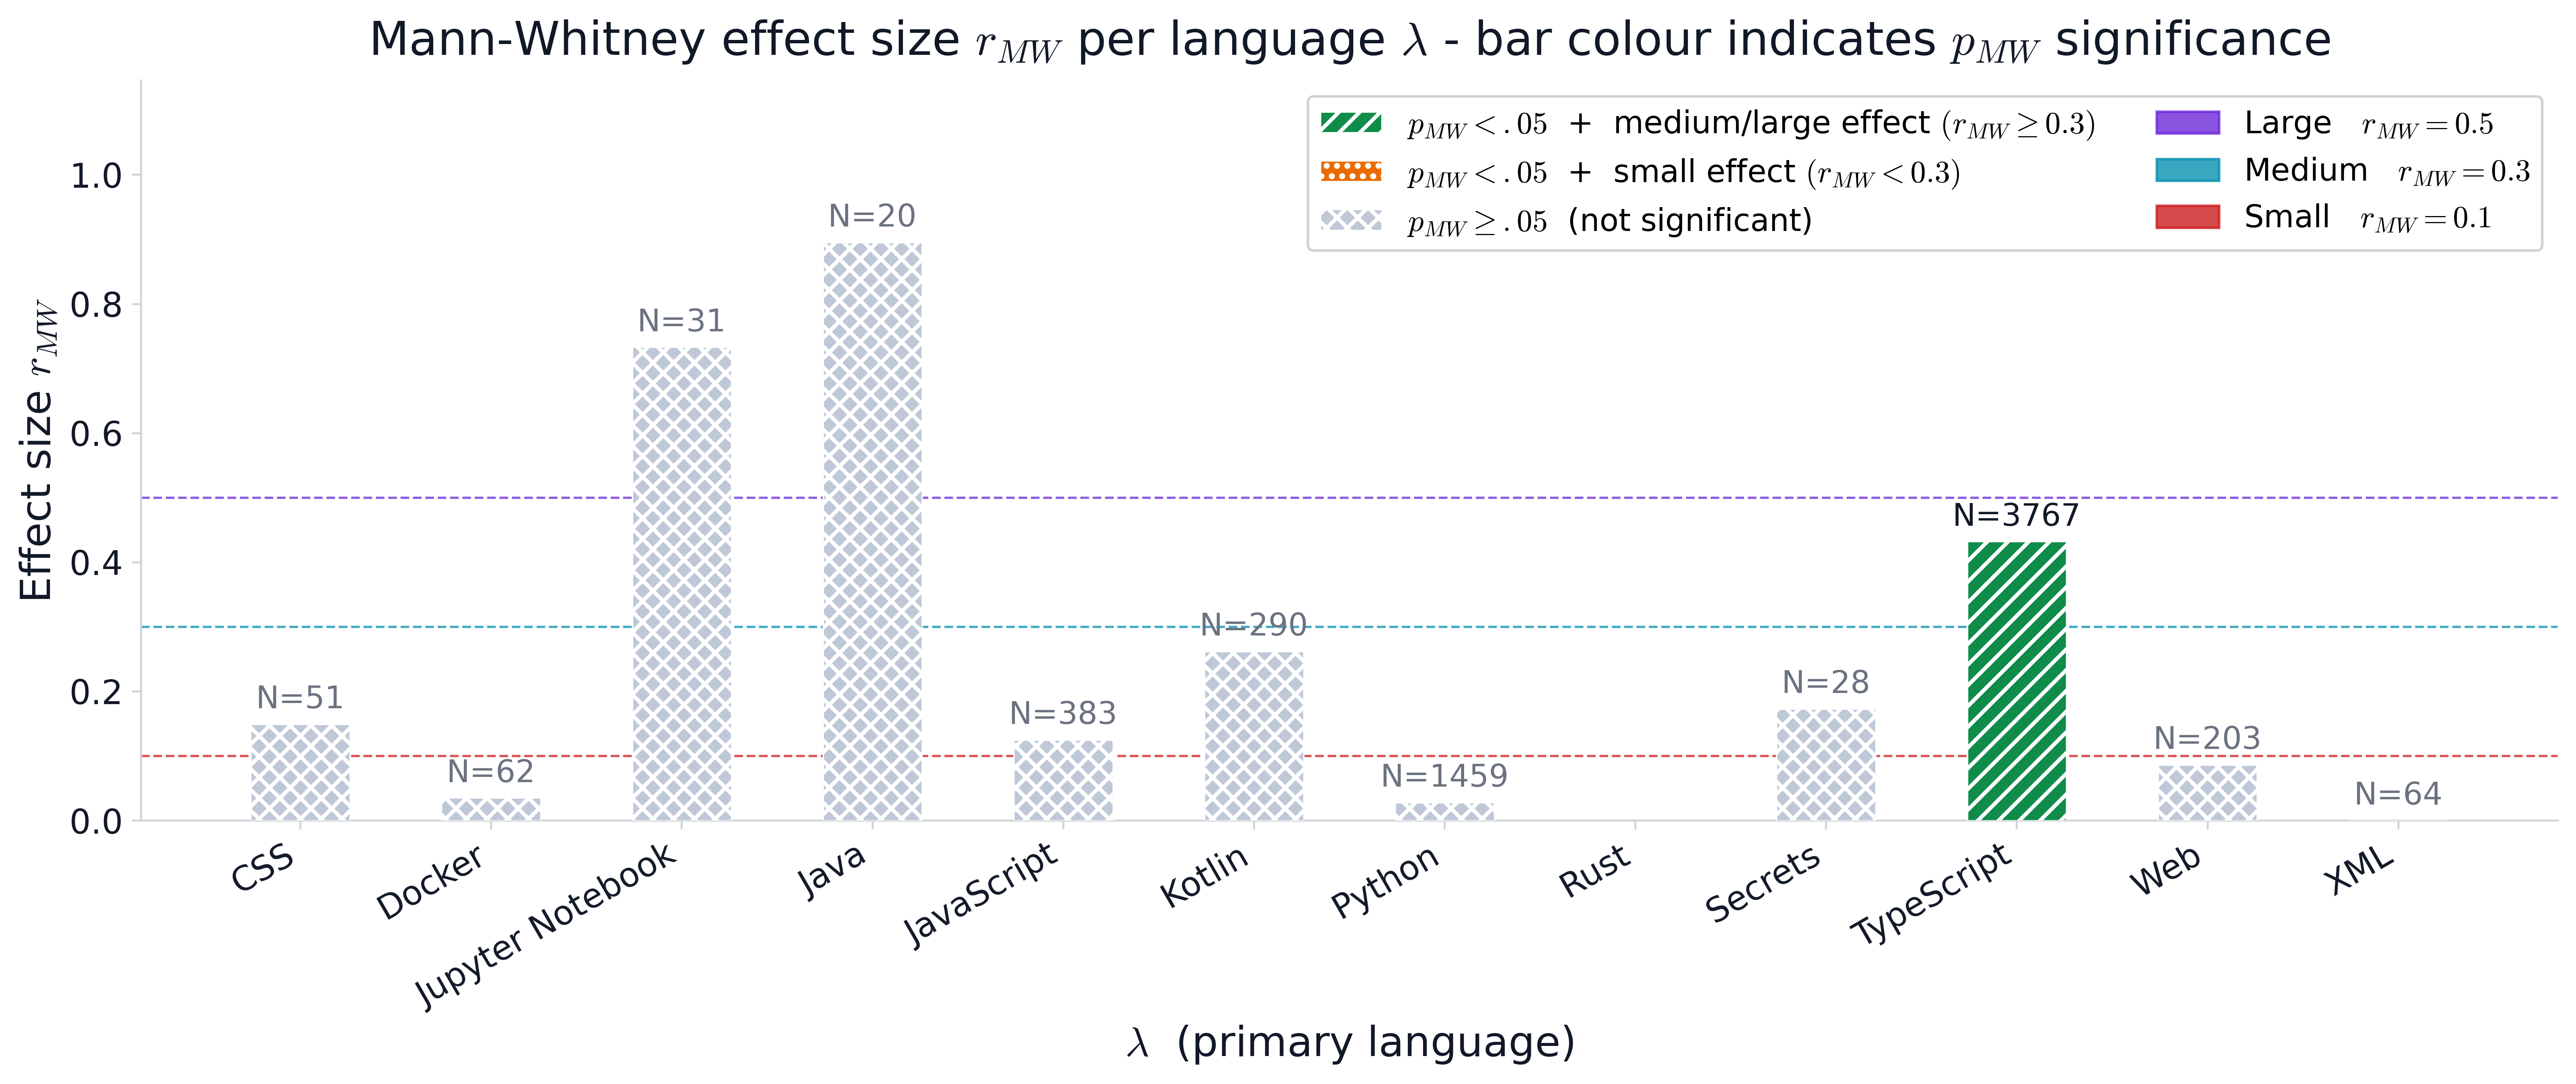

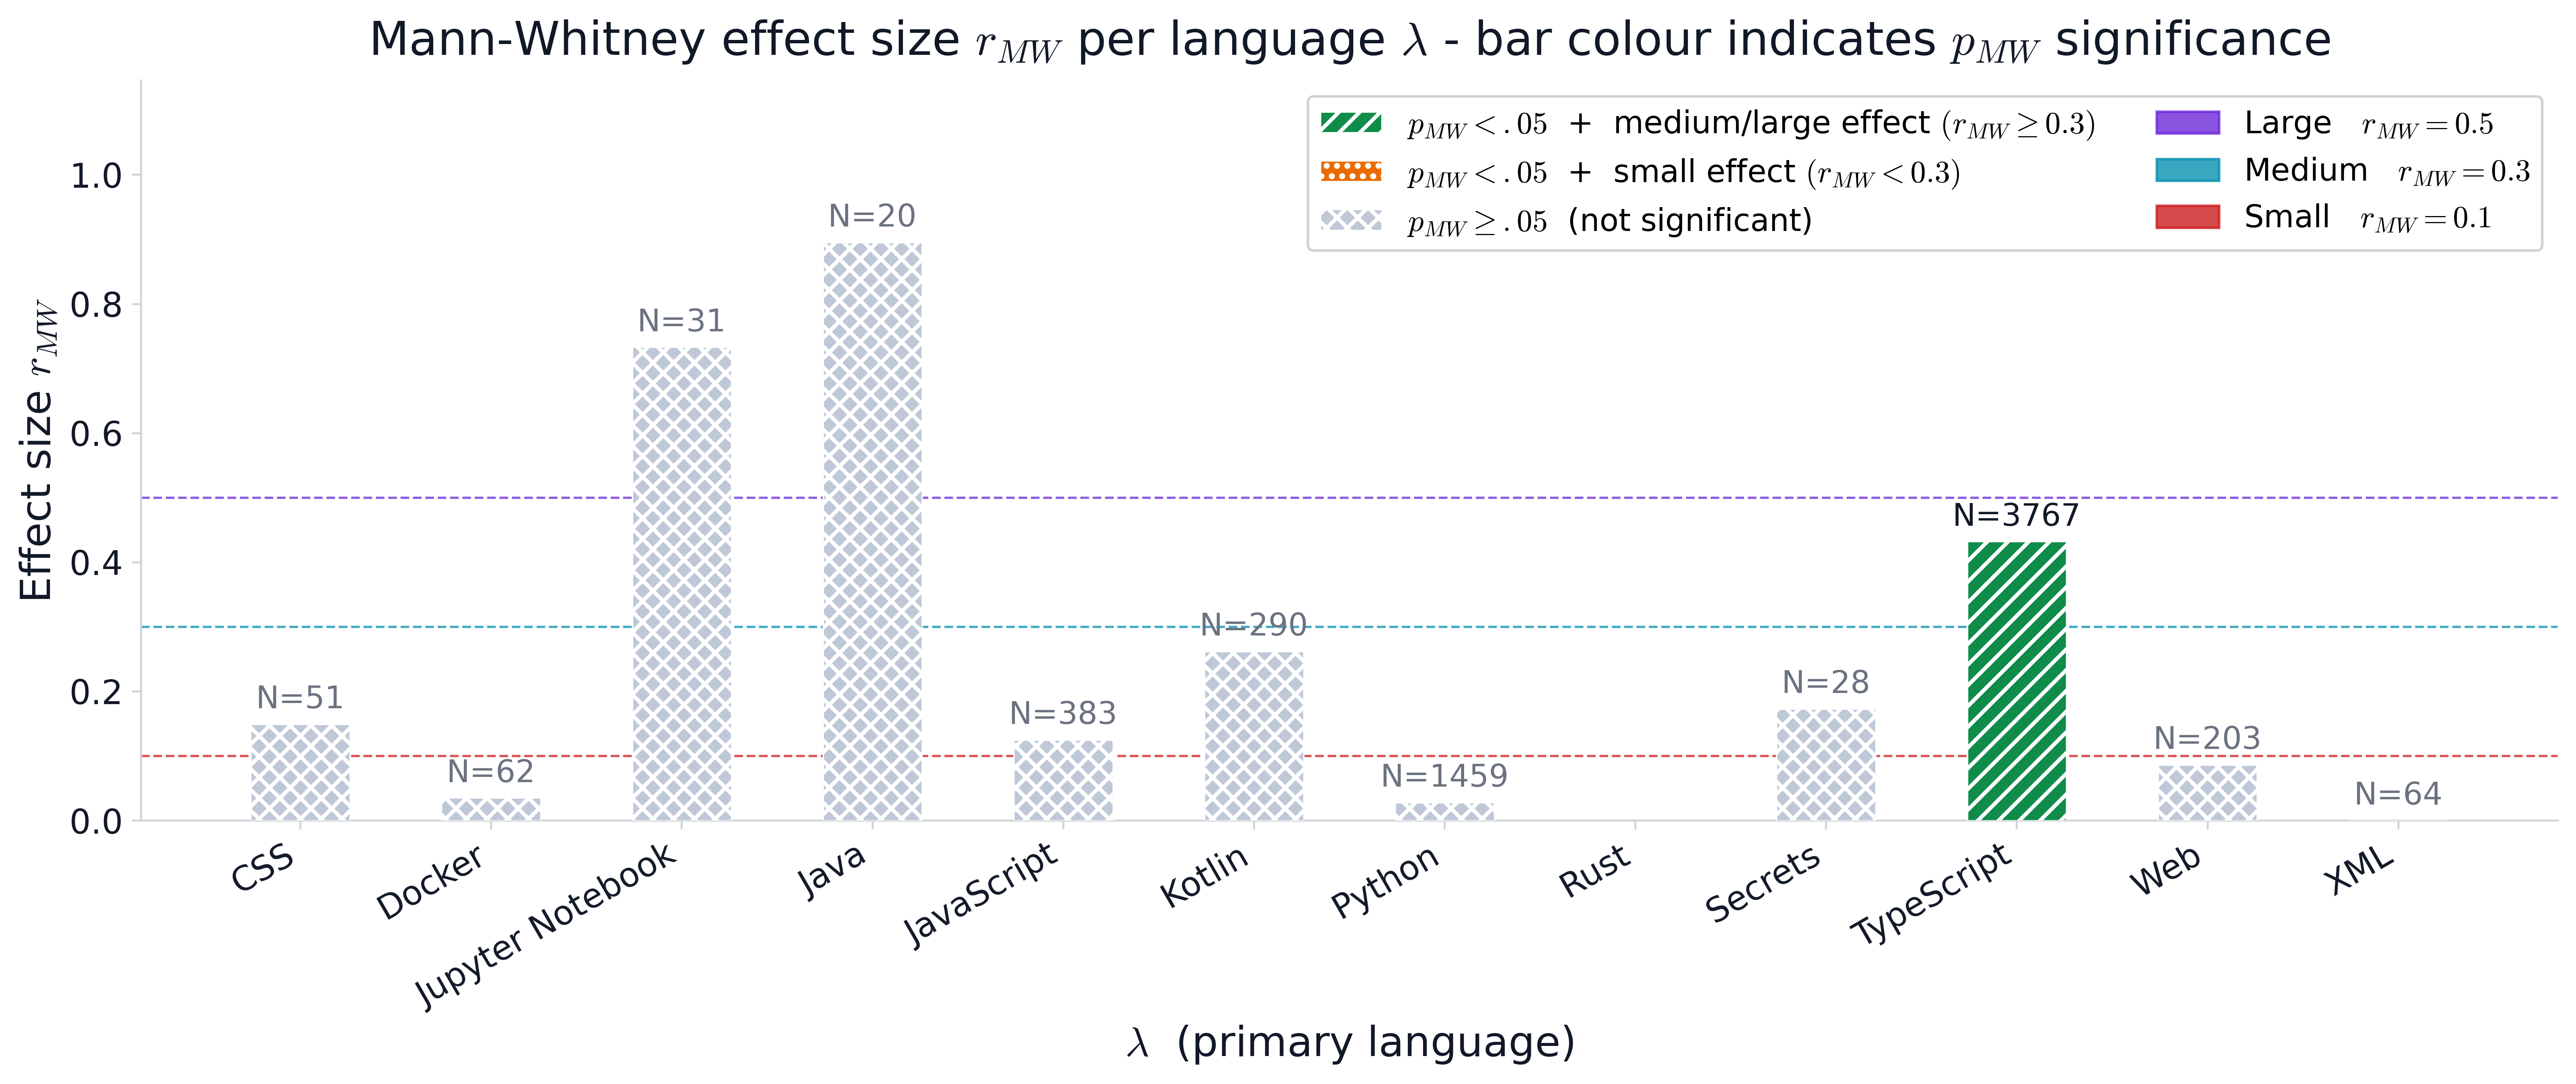

In [137]:
df_sensitivity = combined_aiup_sqp.copy()
df_sensitivity["year"] = pd.to_datetime(df_sensitivity["date"], utc=True).dt.year

df_sensitivity = df_sensitivity[df_sensitivity["year"] >= 2021]

results_df_sensitivity = extract_language_stats(df_sensitivity, ai_prob_col, size_col, high_threshold)
plot_h1_normalised_churn(results_df_sensitivity, high_threshold=0.6)
plot_h1_correlation(results_df_sensitivity)
plot_h1_effect_size(results_df_sensitivity)

\begin{tabular}{lllllllllllll}
\toprule
Metric & 0 & 1 & 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 \\
\midrule
Language & css & docker & ipynb & java & js & kotlin & py & rust & secrets & ts & web & xml \\
N & 71 & 147 & 31 & 33 & 2960 & 290 & 2514 & 11 & 38 & 6032 & 529 & 64 \\
Median contribution (High AI) & 12.500 & 6.000 & 5.000 & 6.000 & 19.000 & 3.000 & 21.000 & NaN & 36.000 & 9.000 & 15.000 & 37.000 \\
Median contribution (Low AI) & 28.000 & 15.500 & 219.000 & 29.000 & 43.000 & 23.000 & 27.000 & 119.000 & 27.000 & 38.000 & 25.000 & 37.000 \\
Mean contribution (High AI) & 54.062 & 17.913 & 5.000 & 6.000 & 1774.880 & 47.875 & 116.045 & NaN & 101.800 & 38.609 & 195754.172 & 37.000 \\
Mean contribution (Low AI) & 101.218 & 60.976 & 908.833 & 71.406 & 333.993 & 62.238 & 154.527 & 121.455 & 55.667 & 1446.073 & 1429.742 & 114.841 \\
Mean contribution (High AI, norm.) & 0.597 & 0.330 & 0.006 & 0.086 & 4.591 & 0.774 & 0.785 & NaN & 1.649 & 0.028 & 16.201 & 0.326 \\
Mean contribution (Low A

,r_mw(contribution|ai_group),r_spearman(contribution~ai_prob),Language
2,0.7330,-0.0330,ipynb
1,0.3260,-0.2410,docker
0,0.1670,-0.0380,css
10,0.0820,-0.0050,web


/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_78943/1441521893.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(results_df["Language"], rotation=45, ha="right")
/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_78943/1441521893.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax4.set_xticklabels(results_df["Language"], rotation=45, ha="right")


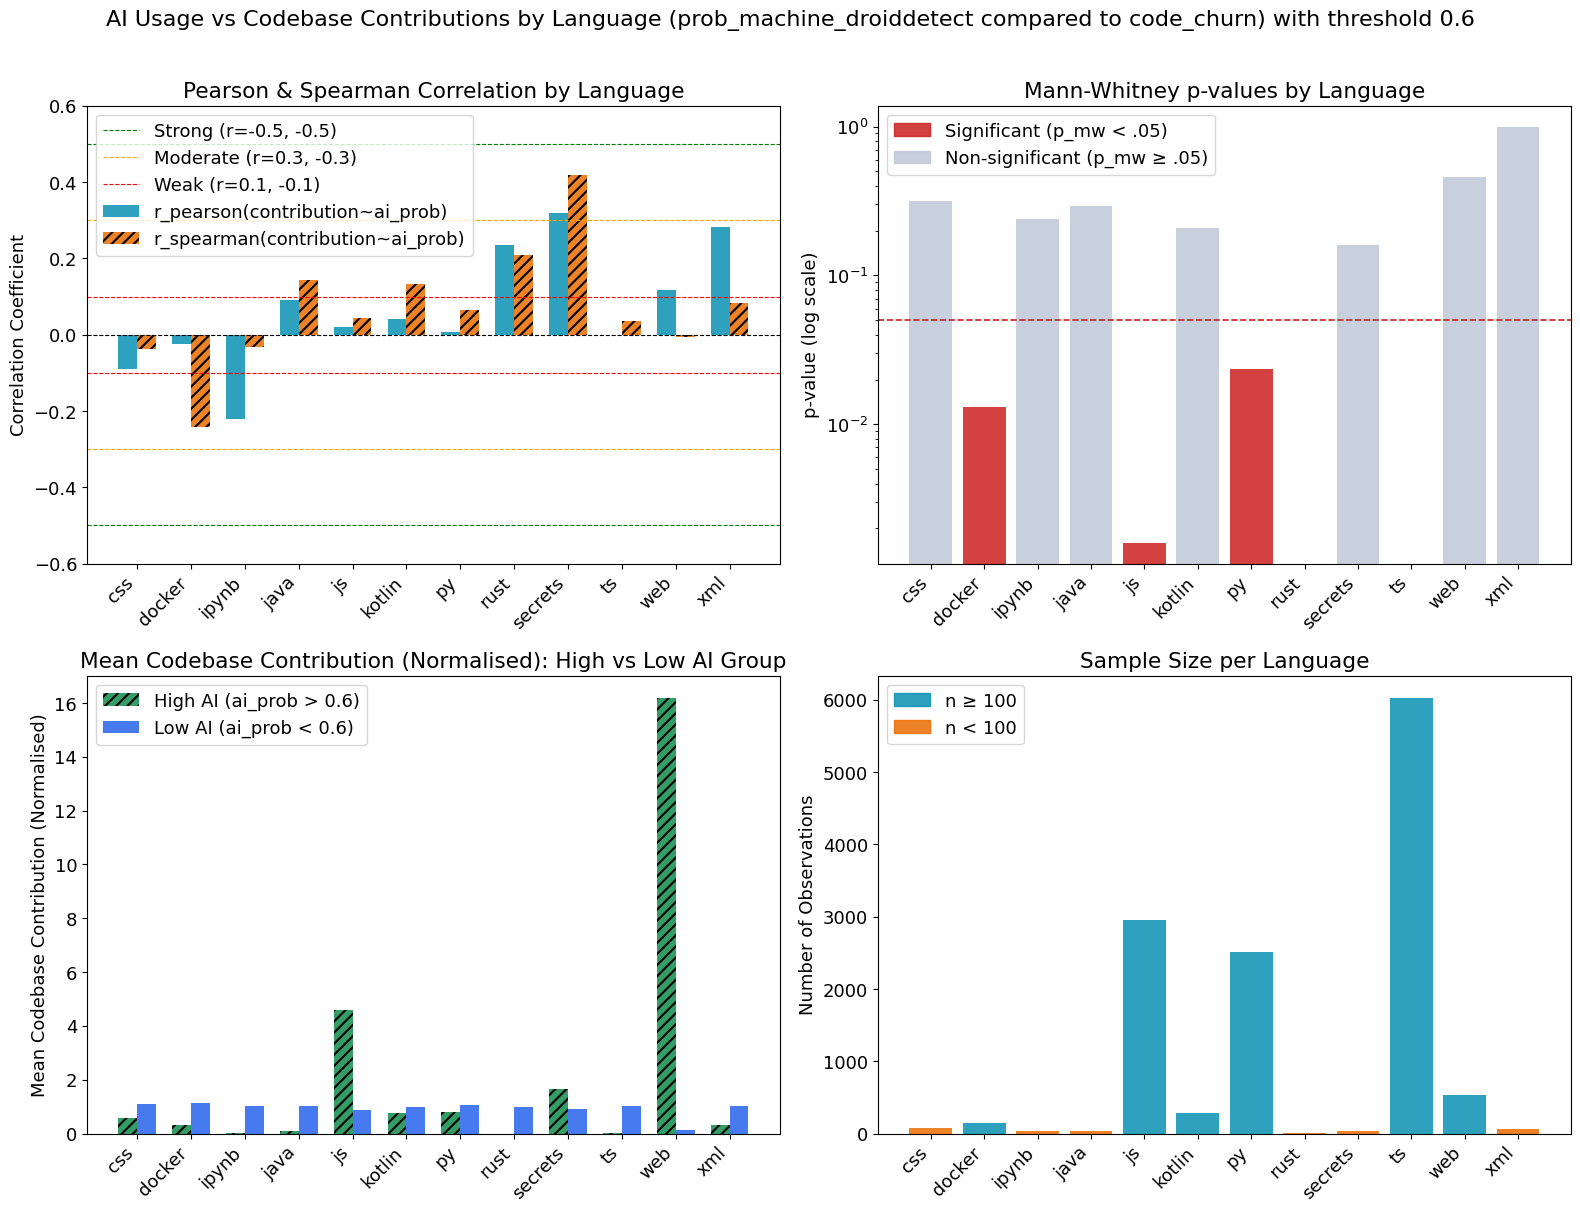

% Table 1: Descriptive Statistics
\begin{table}
\caption{Statistical comparison of codebase size between high and low AI usage groups per language using prob_machine_droiddetect (1/2)}
\label{tab:stat_tests_prob\_machine\_droiddetect_1}
\begin{tabular}{lrrrrr}
\toprule
Language & N & Median contribution (High AI) & Median contribution (Low AI) & Mean contribution (High AI, norm.) & Mean contribution (Low AI, norm.) \\
\midrule
css & 71 & 12.5000 & 28.0000 & 0.5970 & 1.1170 \\
docker & 147 & 6.0000 & 15.5000 & 0.3300 & 1.1240 \\
ipynb & 31 & 5.0000 & 219.0000 & 0.0060 & 1.0330 \\
java & 33 & 6.0000 & 29.0000 & 0.0860 & 1.0290 \\
js & 2960 & 19.0000 & 43.0000 & 4.5910 & 0.8640 \\
kotlin & 290 & 3.0000 & 23.0000 & 0.7740 & 1.0060 \\
py & 2514 & 21.0000 & 27.0000 & 0.7850 & 1.0460 \\
rust & 11 & NaN & 119.0000 & NaN & 1.0000 \\
secrets & 38 & 36.0000 & 27.0000 & 1.6490 & 0.9020 \\
ts & 6032 & 9.0000 & 38.0000 & 0.0280 & 1.0390 \\
web & 529 & 15.0000 & 25.0000 & 16.2010 & 0.1180 \\
xml & 64

In [100]:
df = combined_aiup_sqp

print(
    results_df
    .transpose()
    .reset_index(names="Metric")
    .to_latex(index=False, float_format="%.3f")
)

testdf = results_df[["r_mw(contribution|ai_group)", "r_spearman(contribution~ai_prob)", "Language"]].sort_values(by="r_mw(contribution|ai_group)", ascending=False)
show_sign_disagreement = testdf[
    (testdf["r_mw(contribution|ai_group)"] > 0)    & (testdf["r_spearman(contribution~ai_prob)"] < 0) |
    (testdf["r_mw(contribution|ai_group)"] < 0)    & (testdf["r_spearman(contribution~ai_prob)"] > 0)
]

display(show_sign_disagreement)
# plot_normality(combined_aiup_sqp)
plot_results(results_df, ai_prob_col, size_col, high_threshold)
df_to_latex(results_df, ai_prob_col)

In [101]:
lang_of_interest = "py"

df = df_clean[df_clean['primary_language'] == lang_of_interest]
df_removed_outlier = df[df[size_col] < df[size_col].quantile(0.95)] 

plt.figure(figsize=(10, 6))
sns.scatterplot(x=ai_prob_col, y=size_col, data=df_removed_outlier, alpha=0.5)
plt.xlabel(ai_prob_col)
plt.ylabel(size_col)
plt.title(f"Scatter Plot of AI Usage vs Code Churn ({lang_of_interest})")
plt.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'df_clean' is not defined

In [ ]:
df = combined_aiup_sqp

average_ai_usage = df.groupby("repository_id")["prob_ai_whodunit"].mean()
total_repo_contribution = df.groupby("repository_id")["code_churn"].sum()
repo_size = df.groupby("repository_id")["lines"].max()
primary_language = (
    df.sort_values("date")
      .groupby("repository_id")['languages']
      .last()
      .apply(get_primary_language)
)

# Build regression dataset
repo_df = pd.DataFrame({
    "average_ai_usage": average_ai_usage,
    "total_repo_contribution": total_repo_contribution,
    "repo_size": repo_size,
    "primary_language": primary_language
})

repo_df["log_total_repo_contribution"] = np.log(repo_df["total_repo_contribution"] + 1)
repo_df["log_average_ai_usage"] = repo_df["average_ai_usage"].apply(lambda x: np.log(x + 1))
repo_df["log_repo_size"] = np.log(repo_df["repo_size"] + 1)

display(repo_df.head())

,average_ai_usage,total_repo_contribution,repo_size,primary_language,log_total_repo_contribution,log_average_ai_usage,log_repo_size
repository_id,,,,,,,
2017_KDPRO-SINTEF_BowtieTool,0.0347,340765.0000,380035.0000,web,12.7390,0.0342,12.8480
2017_egrimstad_scalpel,0.0040,37069.0000,5579.0000,js,10.5206,0.0040,8.6269
2018_K-pro-SafeTec_Emergency-Response-CloudFunctions,0.0309,1053.0000,437.0000,js,6.9603,0.0305,6.0822
2018_K-pro-SafeTec_Emergency-Response-Portal,0.0202,29459.0000,7709.0000,js,10.2908,0.0200,8.9503
2018_Kpro11_Aqeous,0.0740,16308.0000,26590.0000,web,9.6995,0.0714,10.1883


/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_67307/2255739423.py:37: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  mw_stat, mw_pval = stats.mannwhitneyu(high, low, alternative='two-sided')
/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_67307/2255739423.py:40: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat, t_pval = stats.ttest_ind(high, low)
/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_67307/2255739423.py:37: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  mw_stat, mw_pval = stats.mannwhitneyu(high, low, alternative='two-sided')
/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_67307/2255739423.py:40: SmallSampleWarning: One or more sample

Language  N  Median (High AI)  Median (Low AI)  Mean (High AI)  Mean (Low AI)  Mean (High AI) (Normalised)  Mean (Low AI) (Normalised)  MW U  MW p   t  t p  Pearson r  Pearson p  Spearman r  Spearman p Normal?
      js 17               NaN        5117.0000             NaN     82459.2940                          NaN                      1.0000   NaN   NaN NaN  NaN     0.2330     0.3678      0.2280      0.3789      No
      py 21               NaN        3559.0000             NaN    119932.6190                          NaN                      1.0000   NaN   NaN NaN  NaN     0.1430     0.5362      0.0060      0.9777      No
      ts 31               NaN        7093.0000             NaN     11657.5810                          NaN                      1.0000   NaN   NaN NaN  NaN    -0.0760     0.6839      0.0190      0.9177      No


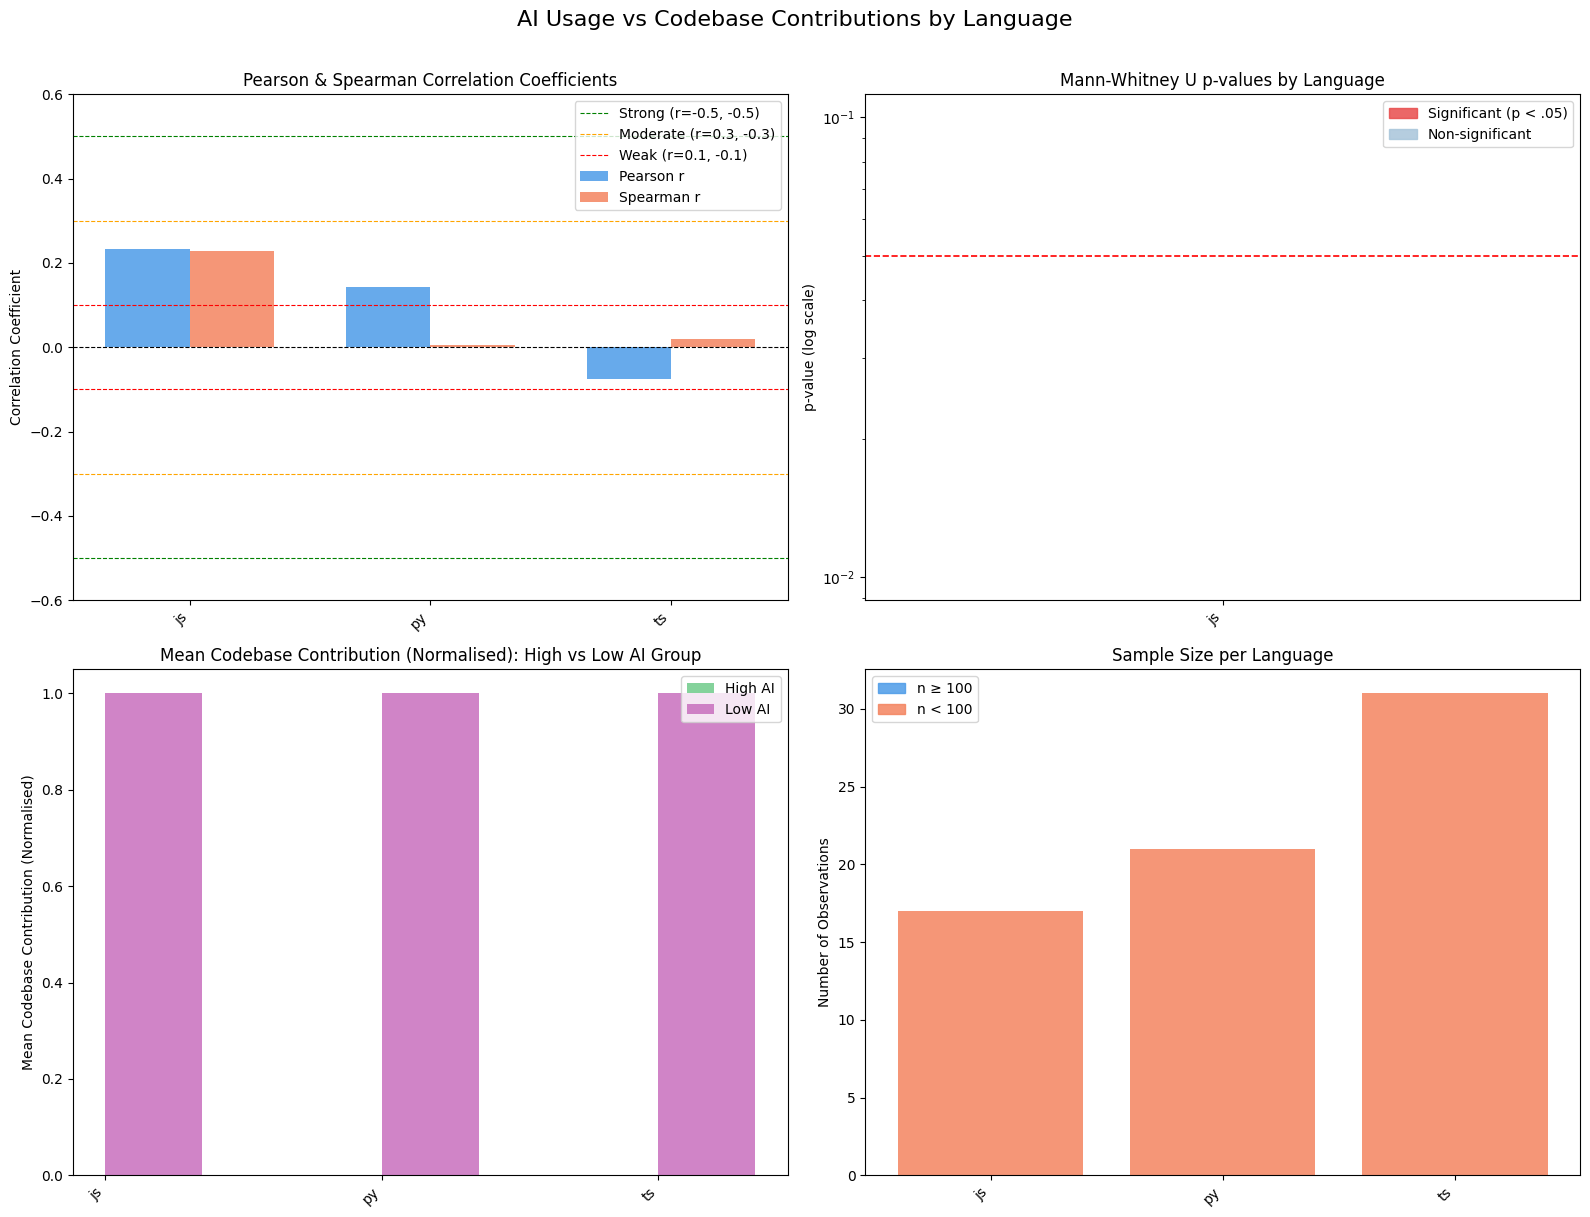

In [ ]:
size_col = "repo_size"
ai_prob_col = "average_ai_usage"

results_df = extract_language_stats(repo_df, ai_prob_col, size_col)
plot_results(results_df)

In [ ]:
def compare_thresholds(df, ai_prob_col, size_col, thresholds):
    """
    Run extract_language_stats across multiple thresholds and compare results.
    thresholds: list of either float values or 'median' 
    """
    all_results = []

    for threshold in thresholds:
        df_thresh = df.copy()

        # Fixed threshold split
        df_thresh['primary_language'] = df['primary_language']  # preserve
        df_thresh[ai_prob_col] = df[ai_prob_col]

        df_thresh['_override_threshold'] = threshold
        results_df = _extract_with_fixed_threshold(df_thresh, ai_prob_col, size_col, threshold)
        results_df['Threshold'] = str(threshold)

        all_results.append(results_df)

    return all_results

def _extract_with_fixed_threshold(df, ai_prob_col, size_col, threshold):
    """Same as extract_language_stats but with a fixed threshold instead of median split."""
    df = df.copy()
    languages = df['primary_language'].dropna().unique()
    results = []

    for lang in sorted(languages):
        lang_df = df[df['primary_language'] == lang].dropna(subset=[ai_prob_col, size_col])
        lang_df["ai_group"] = lang_df[ai_prob_col].apply(lambda x: "High" if x >= threshold else "Low")

        if len(lang_df) < 10:
            continue

        high = lang_df[lang_df["ai_group"] == "High"][size_col]
        low  = lang_df[lang_df["ai_group"] == "Low"][size_col]

        if len(high) < 3 or len(low) < 3:
            continue

        _, shap_p_high = stats.shapiro(high) if len(high) >= 3 else (None, None)
        _, shap_p_low  = stats.shapiro(low)  if len(low)  >= 3 else (None, None)
        normal = (shap_p_high is not None and shap_p_high > 0.05 and
                  shap_p_low  is not None and shap_p_low  > 0.05)

        mw_stat, mw_pval   = stats.mannwhitneyu(high, low, alternative='two-sided')
        t_stat,  t_pval    = stats.ttest_ind(high, low)
        pearson_r,  pearson_p  = stats.pearsonr(lang_df[ai_prob_col], lang_df[size_col])
        spearman_r, spearman_p = stats.spearmanr(lang_df[ai_prob_col], lang_df[size_col])

        results.append({
            "Language":         lang,
            "N":                len(lang_df),
            "N High":           len(high),
            "N Low":            len(low),
            "Median (High AI)": round(high.median(), 3),
            "Median (Low AI)":  round(low.median(), 3),
            "MW U":             round(mw_stat, 1),
            "MW p":             round(mw_pval, 4),
            "t":                round(t_stat, 3),
            "t p":              round(t_pval, 4),
            "Pearson r":        round(pearson_r, 3),
            "Pearson p":        round(pearson_p, 4),
            "Spearman r":       round(spearman_r, 3),
            "Spearman p":       round(spearman_p, 4),
            "Normal?":          "Yes" if normal else "No",
        })

    return pd.DataFrame(results)

In [ ]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
all_results = compare_thresholds(combined_aiup_sqp, 'logit_prob_ai_whodunit', 'log_code_churn', thresholds)

for result in all_results:
    print(f"Threshold: {result['Threshold'].iloc[0]}")
    plot_results(result)

KeyError: 'logit_prob_ai_whodunit'

In [ ]:
def conclude_per_threshold(all_results, alpha=0.05):
    for result_df in all_results:
        threshold = result_df['Threshold'].iloc[0]
        print(f"\n{'='*60}")
        print(f"THRESHOLD: {threshold}")
        print(f"{'='*60}")

        significant_mw    = result_df[result_df['MW p'] < alpha]
        significant_spear = result_df[result_df['Spearman p'] < alpha]
        both_significant  = result_df[(result_df['MW p'] < alpha) & (result_df['Spearman p'] < alpha)]

        print(f"\nSignificant MW U test (p < {alpha}):")
        if len(significant_mw) == 0:
            print("  None")
        for _, row in significant_mw.iterrows():
            direction = "larger" if row['Median (High AI)'] > row['Median (Low AI)'] else "smaller"
            print(f"  {row['Language']:10s} (n={row['N']:5d}): High AI repos have {direction} churn "
                  f"(median {row['Median (High AI)']:.2f} vs {row['Median (Low AI)']:.2f}, p={row['MW p']:.4f})")

        print(f"\nSignificant Spearman correlation (p < {alpha}):")
        if len(significant_spear) == 0:
            print("  None")
        for _, row in significant_spear.iterrows():
            direction = "positive" if row['Spearman r'] > 0 else "negative"
            print(f"  {row['Language']:10s} (n={row['N']:5d}): {direction} correlation "
                  f"(r={row['Spearman r']:.3f}, p={row['Spearman p']:.4f})")

        print(f"\nRobust findings (both MW and Spearman significant):")
        if len(both_significant) == 0:
            print("  None")
        for _, row in both_significant.iterrows():
            print(f"  {row['Language']:10s}: MW p={row['MW p']:.4f}, Spearman r={row['Spearman r']:.3f} p={row['Spearman p']:.4f}")

        print(f"\nOverall conclusion:")
        if len(both_significant) == 0:
            print("  No robust evidence to support H: AI usage correlated with code churn at this threshold.")
        elif len(both_significant) / len(result_df) > 0.5:
            print("  Strong support for H: majority of languages show consistent significant results.")
        else:
            print(f"  Partial support for H: {len(both_significant)}/{len(result_df)} languages show robust results.")

        # Direction of effect
        if len(both_significant) > 0:
            positive = (both_significant['Spearman r'] > 0).sum()
            negative = (both_significant['Spearman r'] < 0).sum()
            if positive > negative:
                print(f"  Direction: Higher AI usage is associated with INCREASED code metric "
                    f"({positive}/{len(both_significant)} robust languages show positive correlation).")
            elif negative > positive:
                print(f"  Direction: Higher AI usage is associated with DECREASED code metric "
                    f"({negative}/{len(both_significant)} robust languages show negative correlation).")
            else:
                print(f"  Direction: Mixed - no consistent direction across robust languages "
                    f"({positive} positive, {negative} negative).")
                
conclude_per_threshold(all_results) 


THRESHOLD: 0.1

Significant MW U test (p < 0.05):
  js         (n= 2960): High AI repos have smaller churn (median 2.07 vs 3.76, p=0.0034)
  py         (n= 2514): High AI repos have smaller churn (median 2.83 vs 3.33, p=0.0001)
  ts         (n= 6032): High AI repos have smaller churn (median 1.95 vs 3.64, p=0.0000)

Significant Spearman correlation (p < 0.05):
  js         (n= 2960): positive correlation (r=0.089, p=0.0000)
  py         (n= 2514): positive correlation (r=0.052, p=0.0096)
  ts         (n= 6032): positive correlation (r=0.116, p=0.0000)

Robust findings (both MW and Spearman significant):
  js        : MW p=0.0034, Spearman r=0.089 p=0.0000
  py        : MW p=0.0001, Spearman r=0.052 p=0.0096
  ts        : MW p=0.0000, Spearman r=0.116 p=0.0000

Overall conclusion:
  Partial support for H: 3/7 languages show robust results.
  Direction: Higher AI usage is associated with INCREASED code metric (3/3 robust languages show positive correlation).

THRESHOLD: 0.2

Significant